# 01-大模型接入、OpenAI 库与提示词工程

本篇对应课程第 1 份课件《01提示词工程》，内容从大模型调用准备开始，依次介绍云端模型接入、环境变量保护 API Key、Ollama 本地模型、OpenAI Python 库、流式输出和历史消息，再补充 LLM 基础、提示词工程、Zero-shot 与 Few-shot，最后完成金融文本分类、信息抽取和文本匹配三个案例。

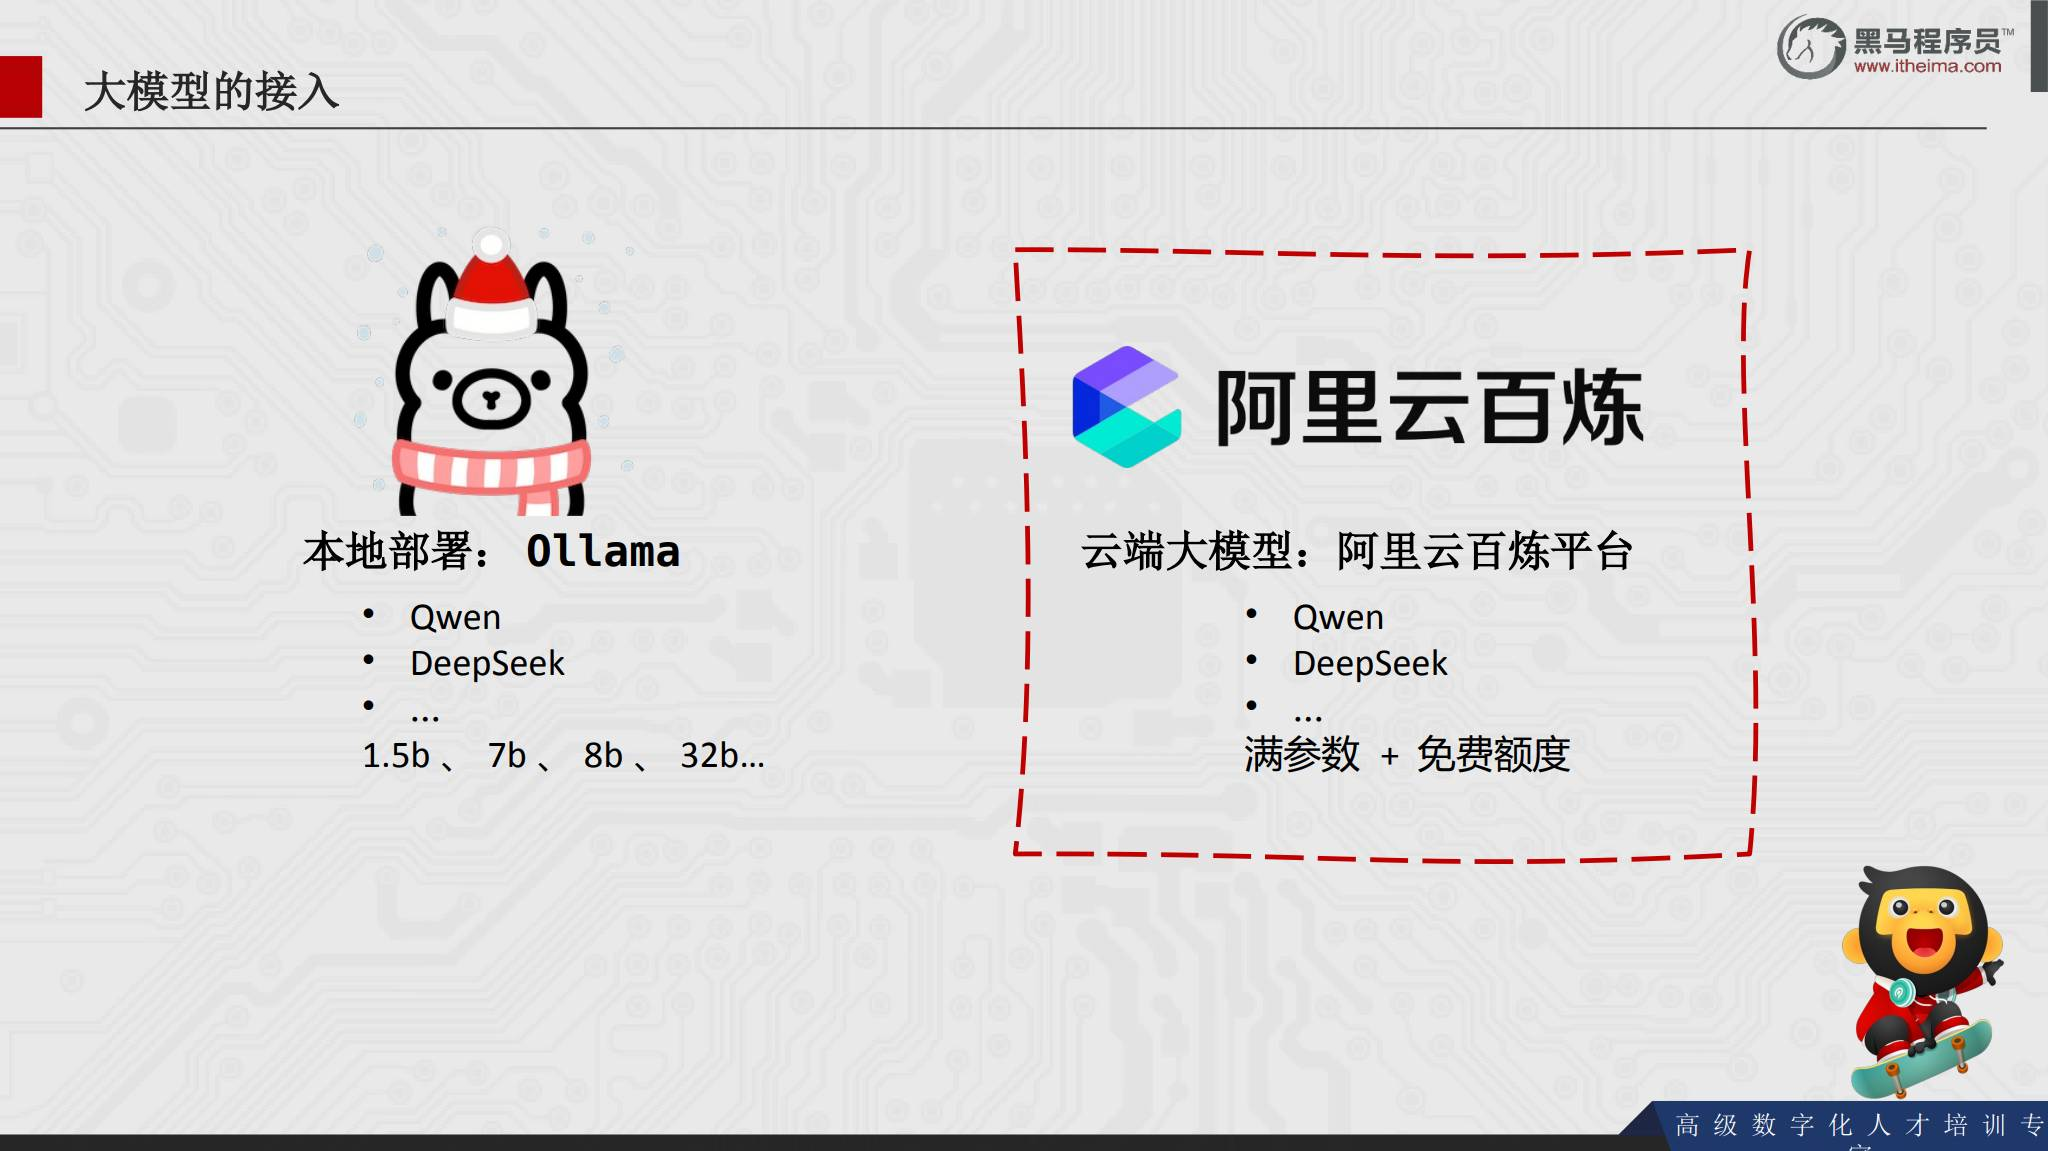


## 1. 大模型的两条接入路线

课程介绍两种模型来源：

| 路线 | 代表方式 | 模型与算力位置 |
| --- | --- | --- |
| 云端大模型 | 阿里云百炼平台 | 云端服务提供模型和算力，按平台额度或服务规则调用 |
| 本地大模型 | Ollama | 模型运行在自己的电脑上，由本地硬件提供算力 |

云端路线的示例模型包括 Qwen、DeepSeek 等；本地路线可以从 Ollama 模型库中选择不同参数规模的开源模型。课程主体使用阿里云百炼，Ollama 作为备用方案。


## 2. 云端模型调用前的准备

课程使用阿里云百炼的通义千问模型作为云端示例，准备流程是：

1. 进入阿里云百炼平台。
2. 注册并登录账号。
3. 按平台要求完成实名认证，可以使用支付宝扫码。
4. 创建 API Key。
5. 安装 OpenAI Python SDK。
6. 复制百炼平台提供的调试代码进行验证。

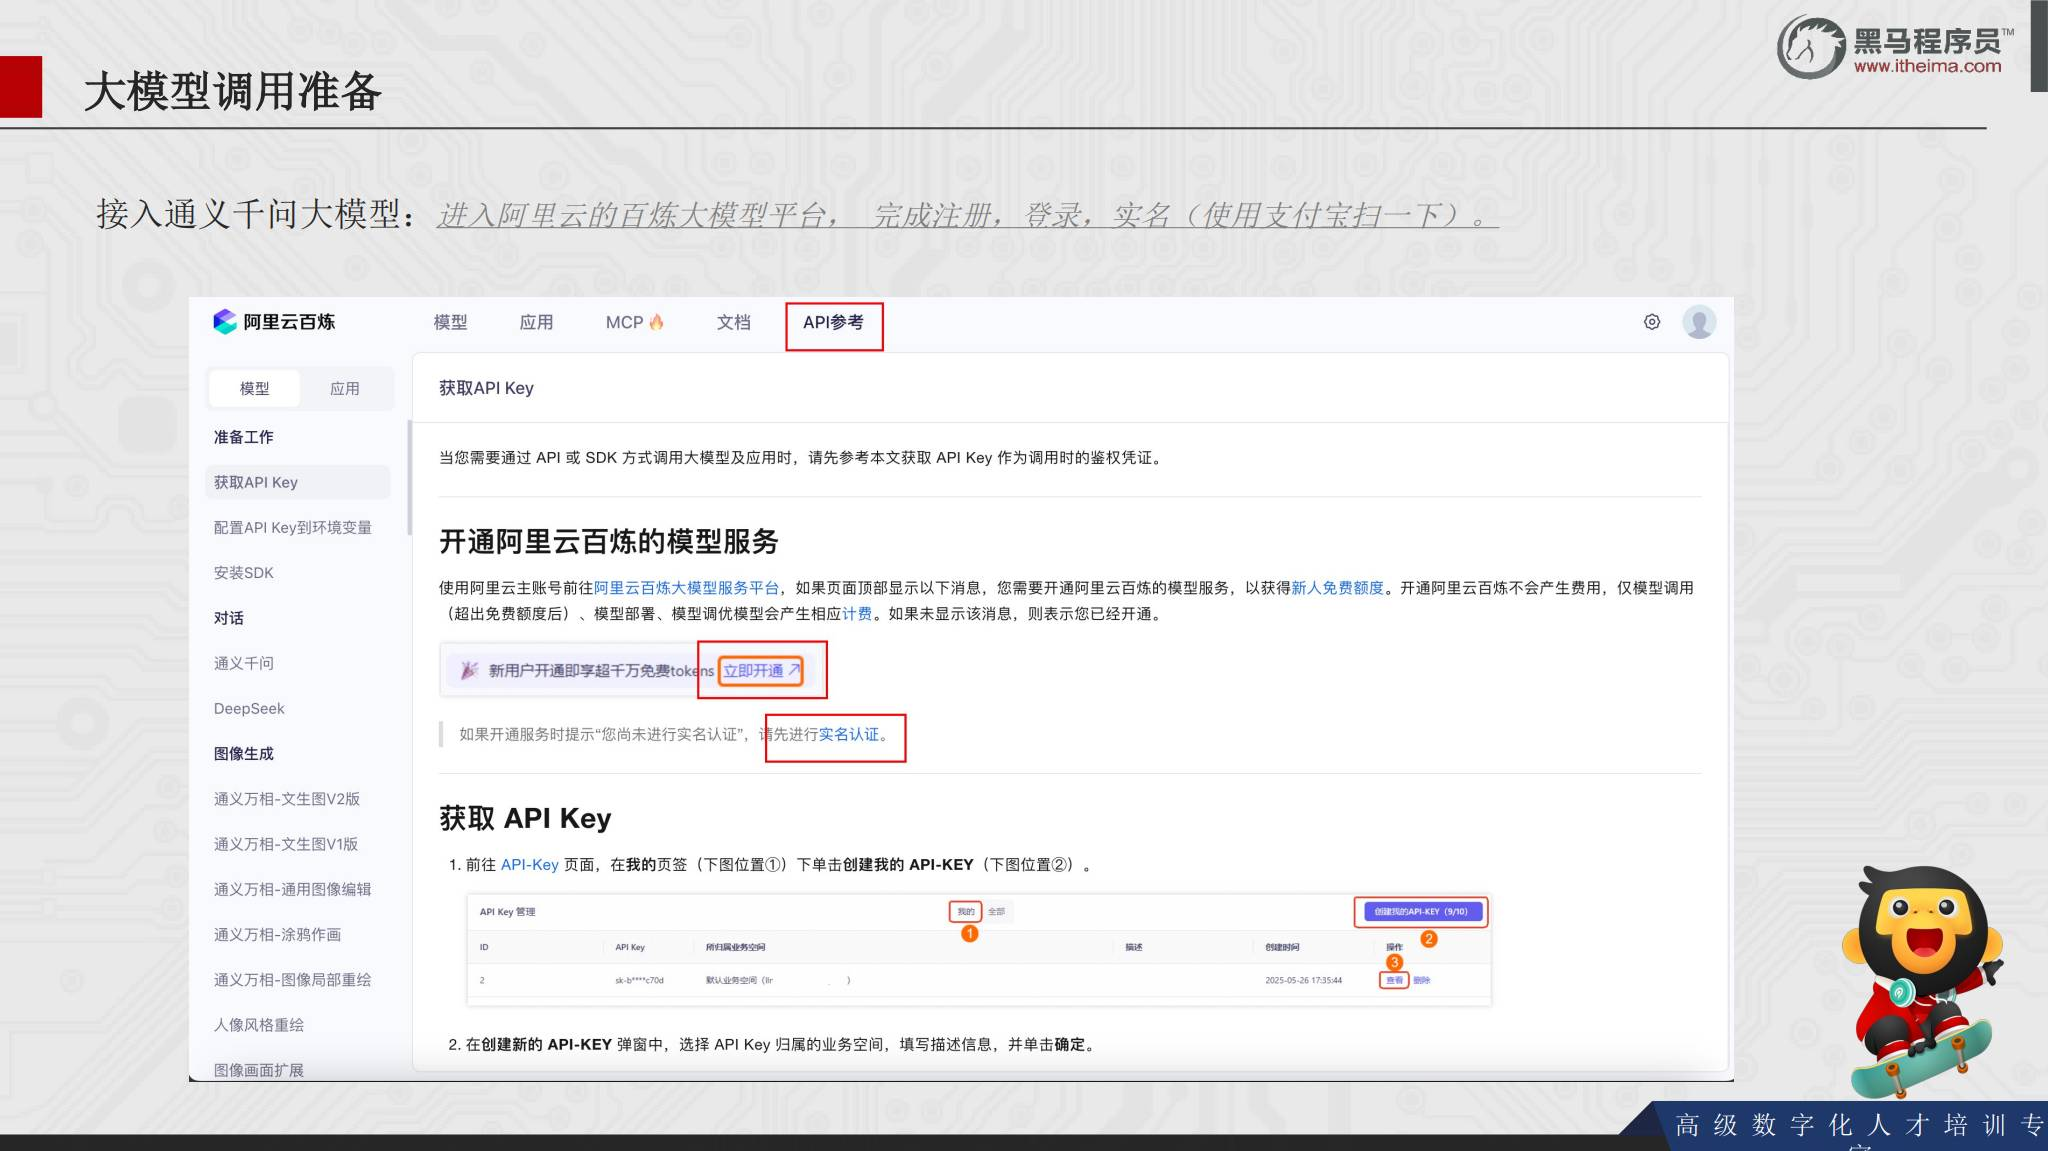

API Key 是访问云端模型的凭证。课件中的演示代码曾直接展示密钥位置，实际使用时必须替换成自己的密钥，并通过环境变量或密钥管理方式保存，不能把真实密钥写进笔记、截图或公开仓库。


## 3. 安装 OpenAI Python 库并运行官方示例

课件使用 OpenAI 兼容接口调用百炼模型。首先安装 `openai`：

```bash
pip install openai
```

然后从百炼平台复制官方提供的测试代码，在本地运行，确认 API Key、模型名称和网络访问均正常。官方示例是最可靠的起点，因为模型服务商的接口地址、模型名和参数可能随平台版本调整。

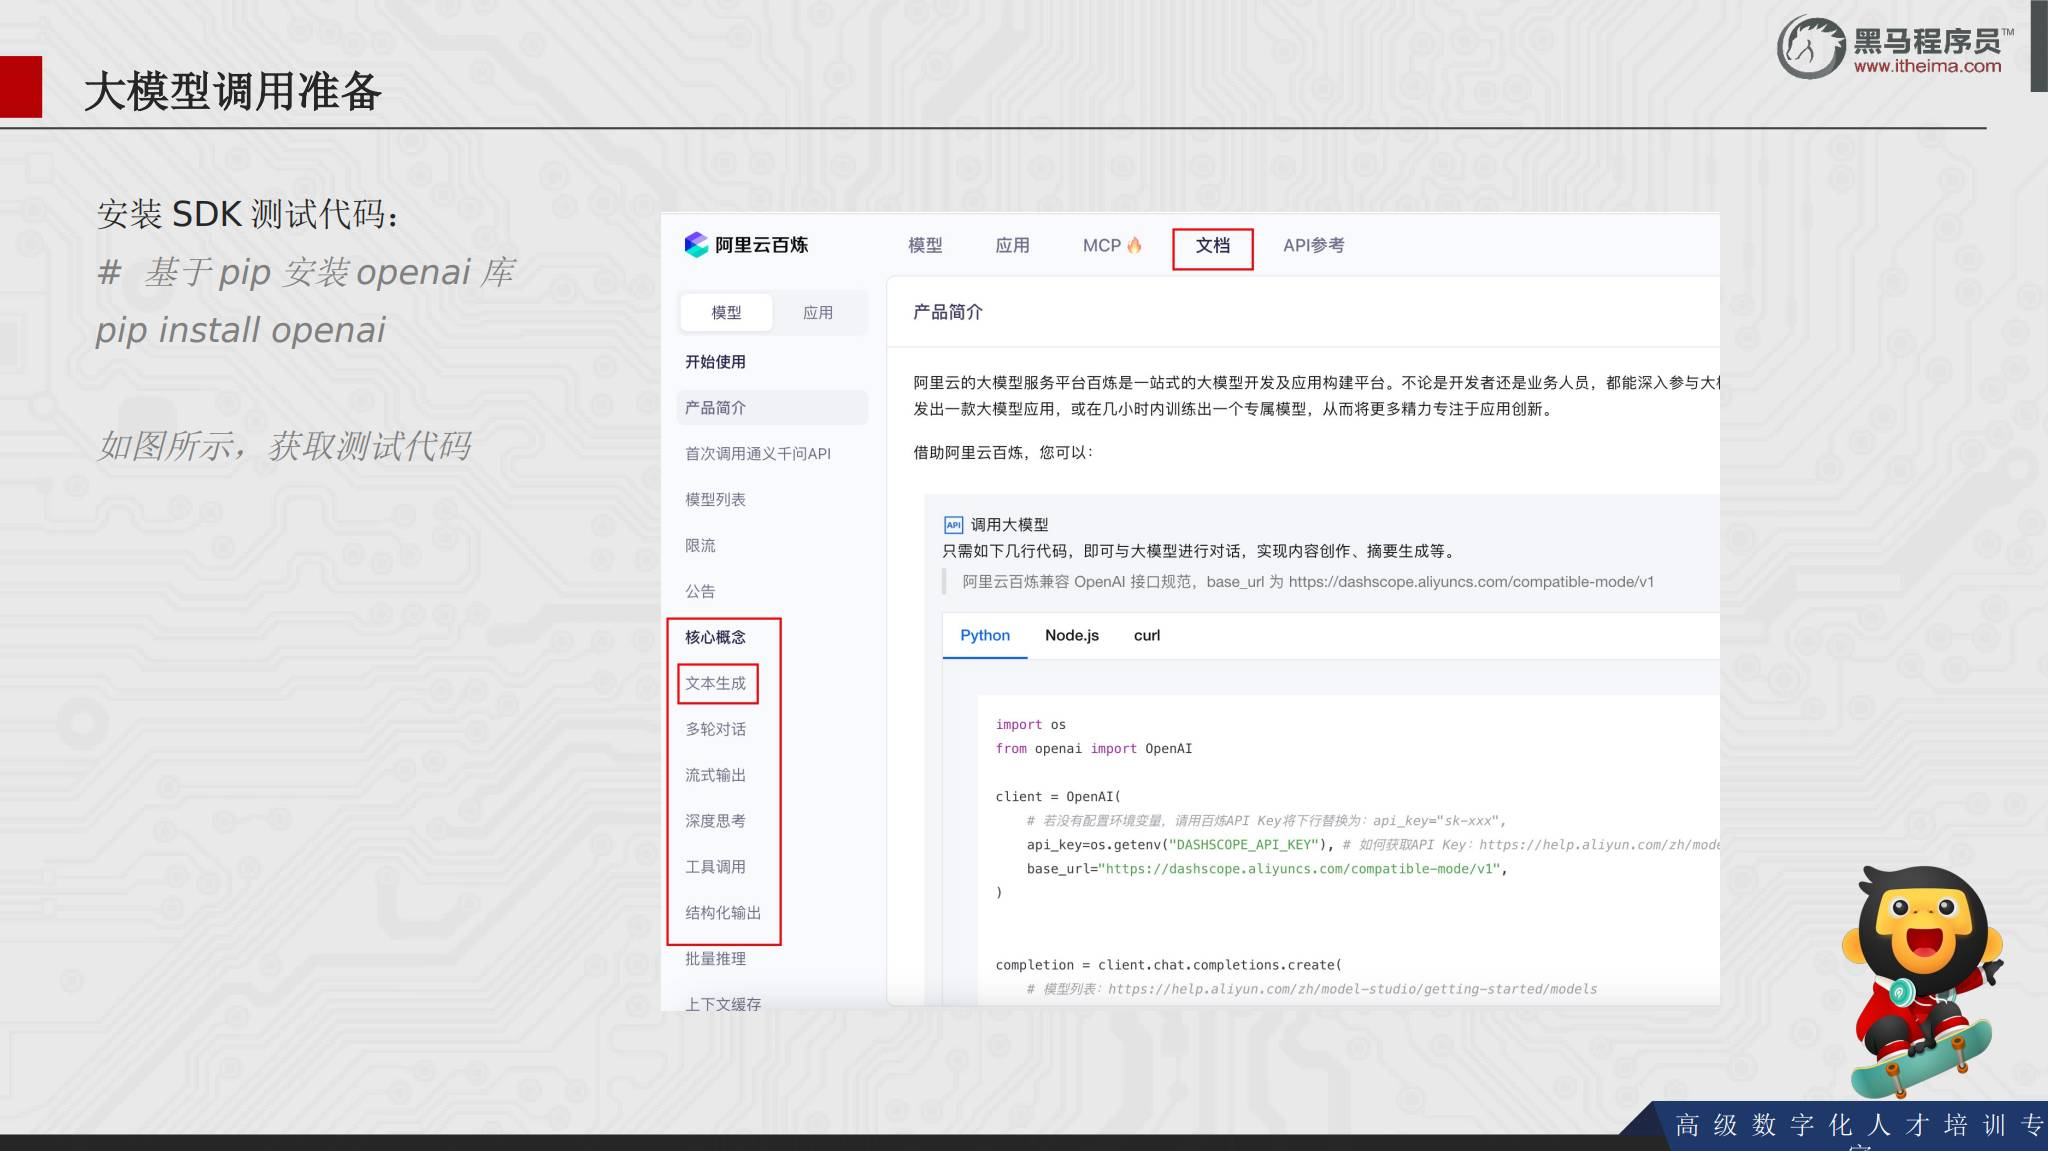


## 4. 用环境变量保护 API Key

把 API Key 直接写在代码里会带来泄露风险。课程建议用环境变量记录密钥，代码只读取变量名。

```python
import os
from openai import OpenAI

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)
```

课程提到的环境变量名包括：

| 变量名 | 用途 |
| --- | --- |
| `OPENAI_API_KEY` | OpenAI 库通用的 API Key 变量名 |
| `DASHSCOPE_API_KEY` | 阿里云百炼示例使用的变量名 |

Windows 可以通过图形化界面配置环境变量；macOS 可以在 `~/.zshrc` 中加入：

```bash
export OPENAI_API_KEY=你的密钥
export DASHSCOPE_API_KEY=你的密钥
```

配置后重启 PyCharm；如果仍未生效，再重启终端或电脑。不要把真实值写入这篇笔记。

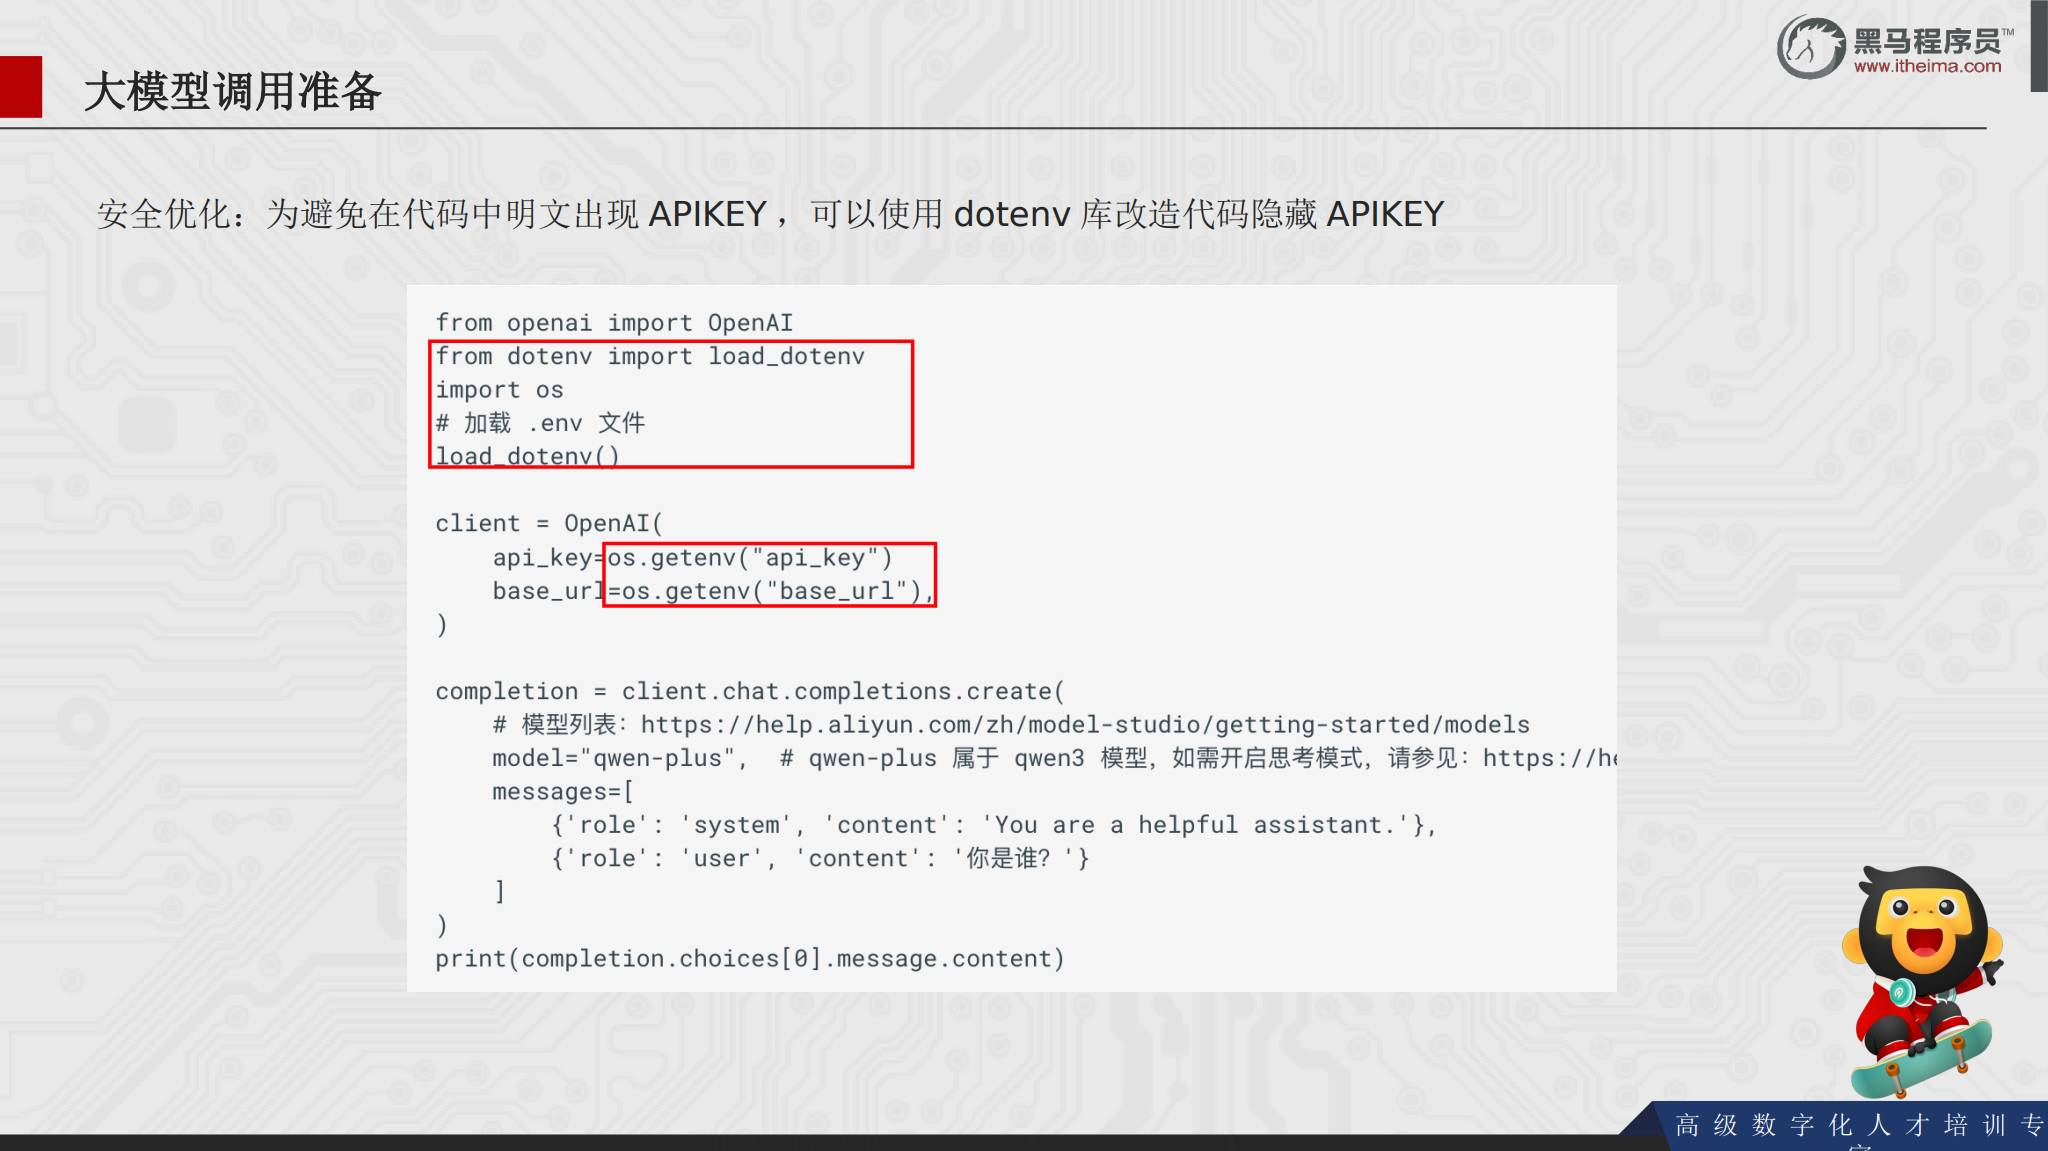


## 5. Chat 模型中的三种角色

调用聊天模型时，`messages` 是一个列表，列表中的每个字典都包含 `role` 和 `content`：

| 角色 | 作用 |
| --- | --- |
| `system` | 设定助手的身份、整体行为和规则，影响后续交互 |
| `assistant` | 表示模型的历史回答，也可以在代码中预先设定 |
| `user` | 表示用户发送的问题、指令或需求 |

多个角色消息按照顺序组成对话上下文。后续调用模型时，模型会结合这些消息理解当前请求。

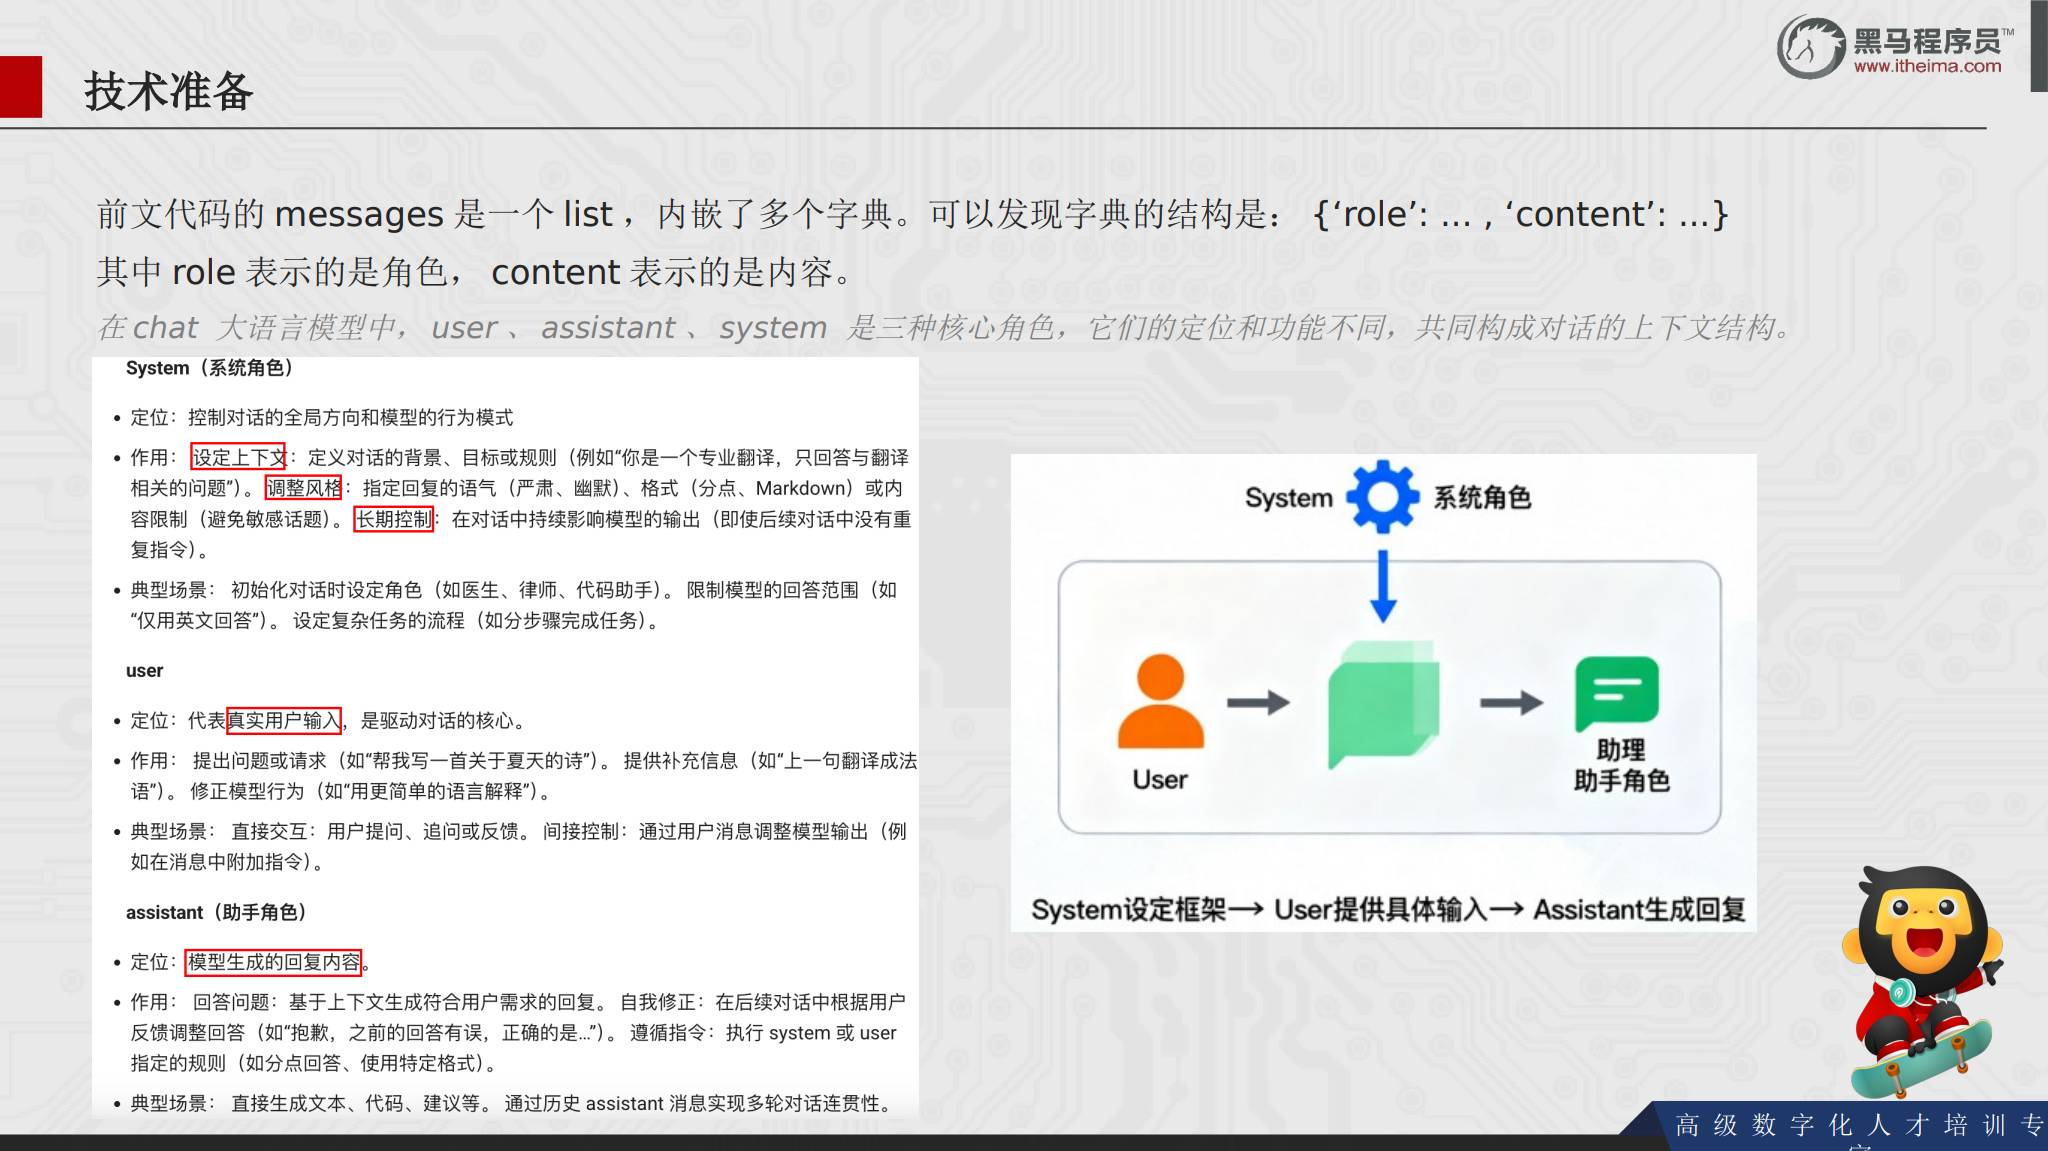


## 6. 用 OpenAI SDK 调用云端模型

从代码角度看，调用百炼兼容接口只需要三步：创建客户端、调用模型、读取结果。

```python
import os
from openai import OpenAI

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

response = client.chat.completions.create(
    model="qwen3-max",
    messages=[
        {"role": "system", "content": "你是一个 Python 编程专家。"},
        {"role": "user", "content": "for 循环输出 1 到 5 的数字"},
    ],
)

print(response.choices[0].message.content)
```

`api_key` 用环境变量读取，`base_url` 指向模型服务商的兼容接口，`model` 选择要调用的模型，`messages` 提供上下文。`response.choices[0].message.content` 是模型生成的文本。

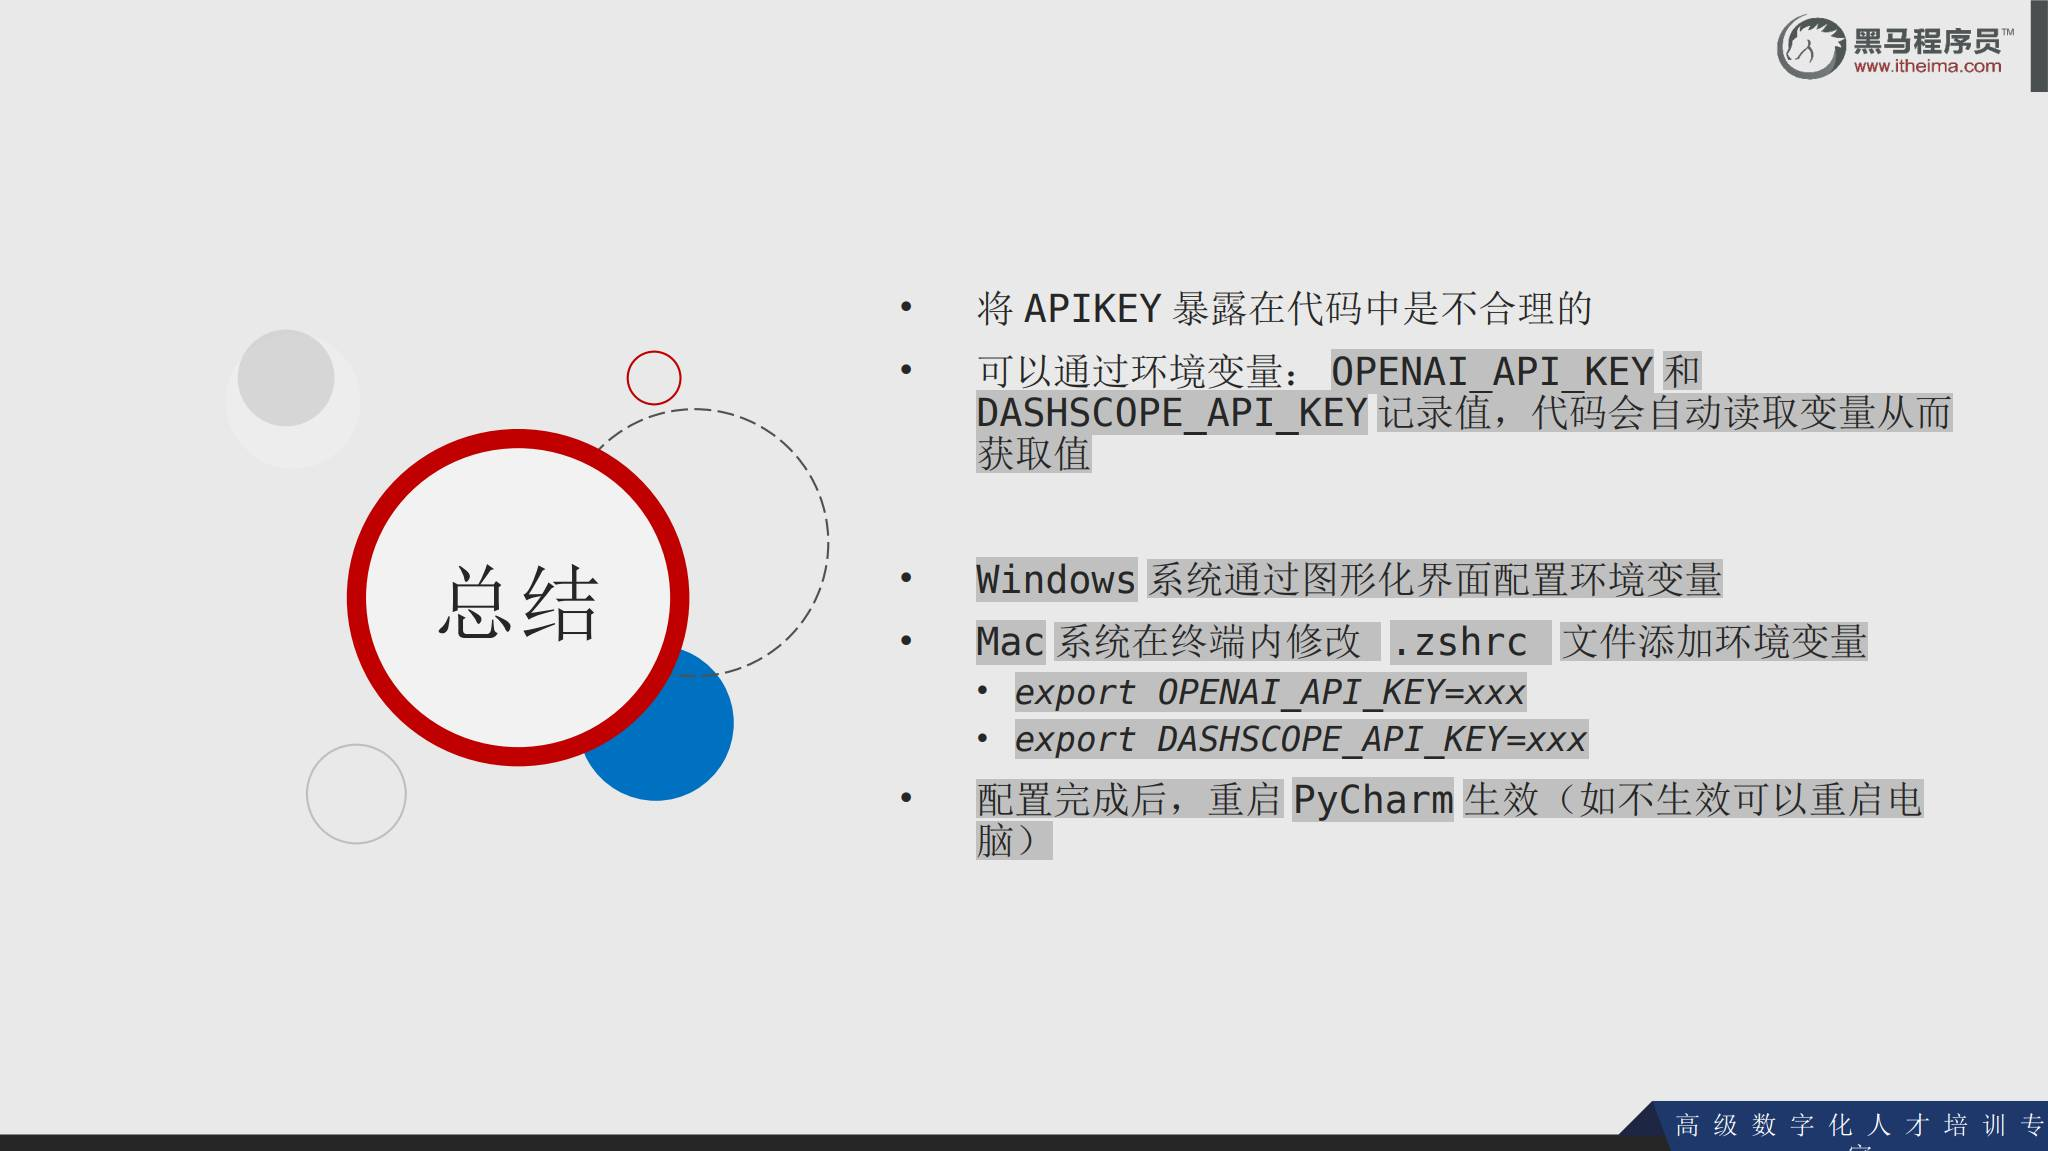


## 7. 流式输出

默认调用会等待完整结果后再返回。课程介绍了流式输出：模型生成一段就返回一段，用户可以更早看到内容。

开启流式输出需要两步：

1. 在 `client.chat.completions.create()` 中设置 `stream=True`。
2. 使用 `for` 循环遍历响应对象，逐段输出内容。

```python
response = client.chat.completions.create(
    model="qwen3-max",
    messages=[
        {"role": "system", "content": "你是一个 Python 编程专家。"},
        {"role": "user", "content": "解释什么是列表推导式。"},
    ],
    stream=True,
)

for chunk in response:
    content = chunk.choices[0].delta.content
    if content:
        print(content, end="", flush=True)
```

流式响应的字段与非流式响应不同，需要从 `delta.content` 读取当前片段。

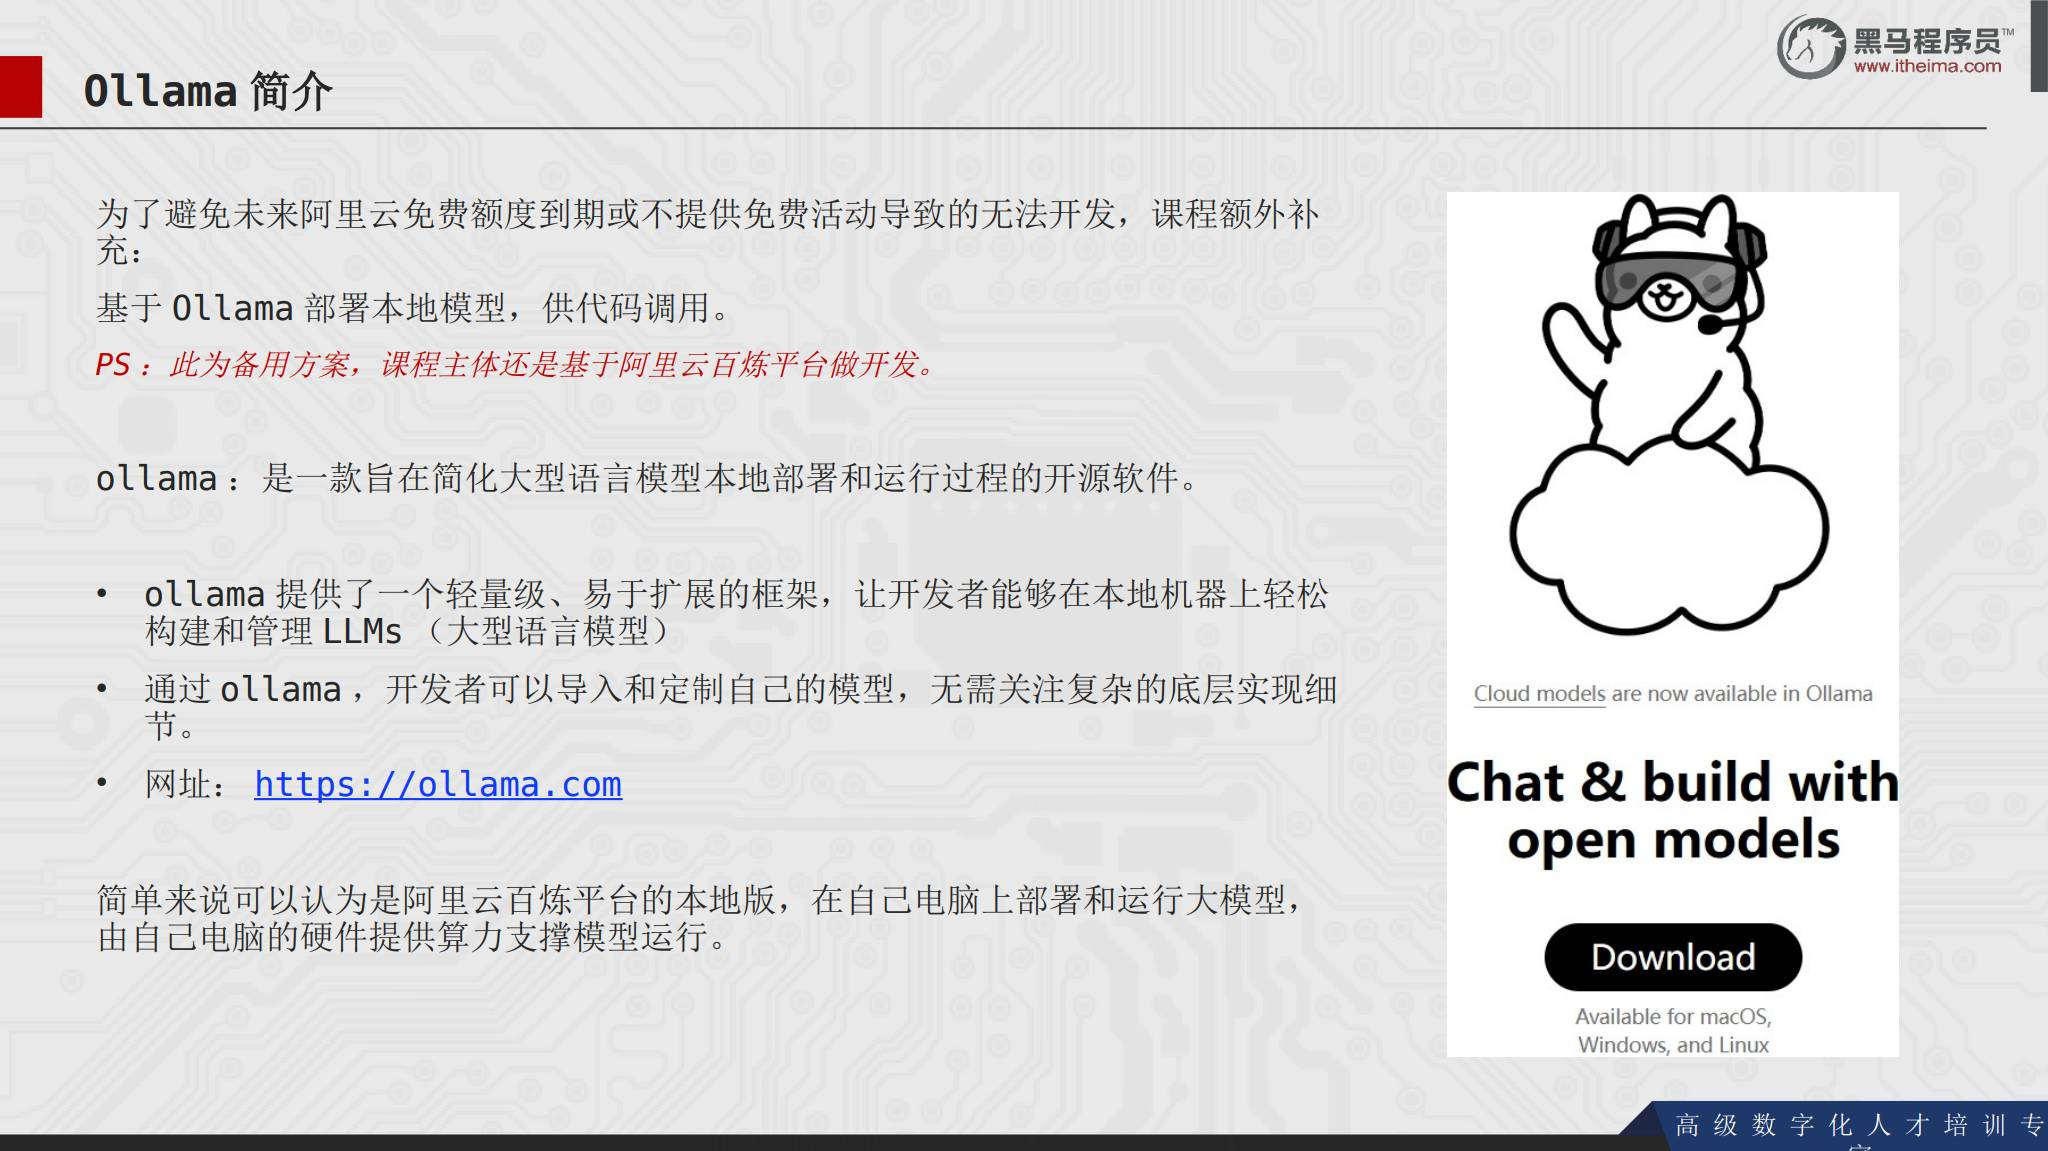


## 8. 携带历史消息调用模型

`messages` 支持放入多条历史消息，因此可以在一次请求中把前面对话传给模型，让模型理解当前问题的上下文。

```python
messages = [
    {"role": "system", "content": "你是 AI 助理，回答很简洁。"},
    {"role": "user", "content": "小明有 2 条宠物狗。"},
    {"role": "assistant", "content": "好的。"},
    {"role": "user", "content": "小红有 3 只宠物猫。"},
    {"role": "assistant", "content": "好的。"},
    {"role": "user", "content": "总共有几个宠物？"},
]
```

示例中的最后一个问题需要结合前面的消息才能回答。课件提醒，这种历史消息只是一次性放在请求中；生产系统需要把消息保存到文件、数据库等持久化工具，在需要时再取出。

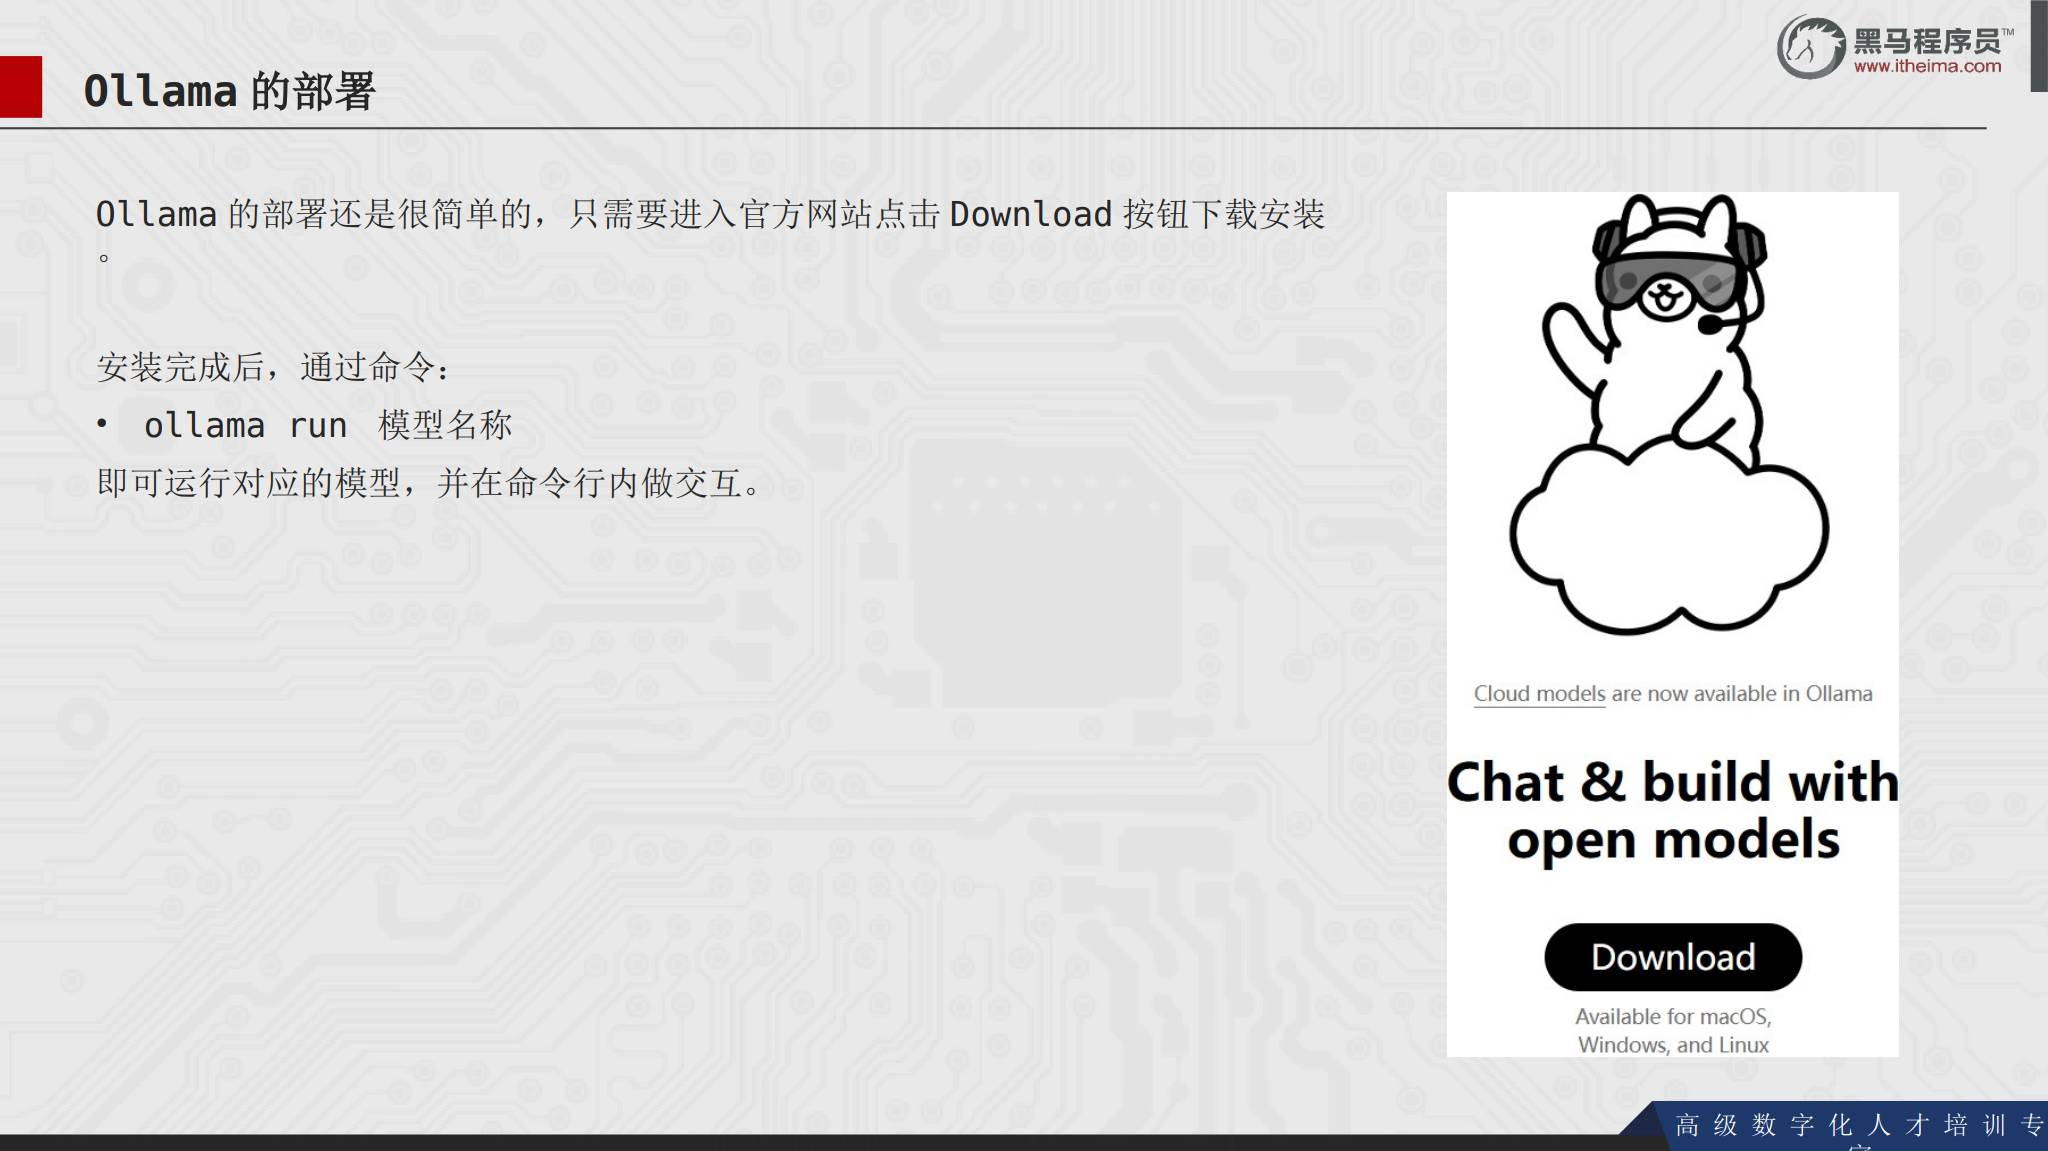


## 9. Ollama：本地模型备用路线

Ollama 是用于简化本地大语言模型部署和运行的开源软件。它提供轻量、可扩展的框架，开发者可以在本地导入、管理和运行模型，不需要处理复杂的底层实现。

课程把 Ollama 理解成云端模型平台的本地替代方案：云端服务由平台提供算力，本地方案由自己的电脑提供算力。课程主体仍然使用阿里云百炼，Ollama 用于备用和本地测试。

官方地址：<https://ollama.com>

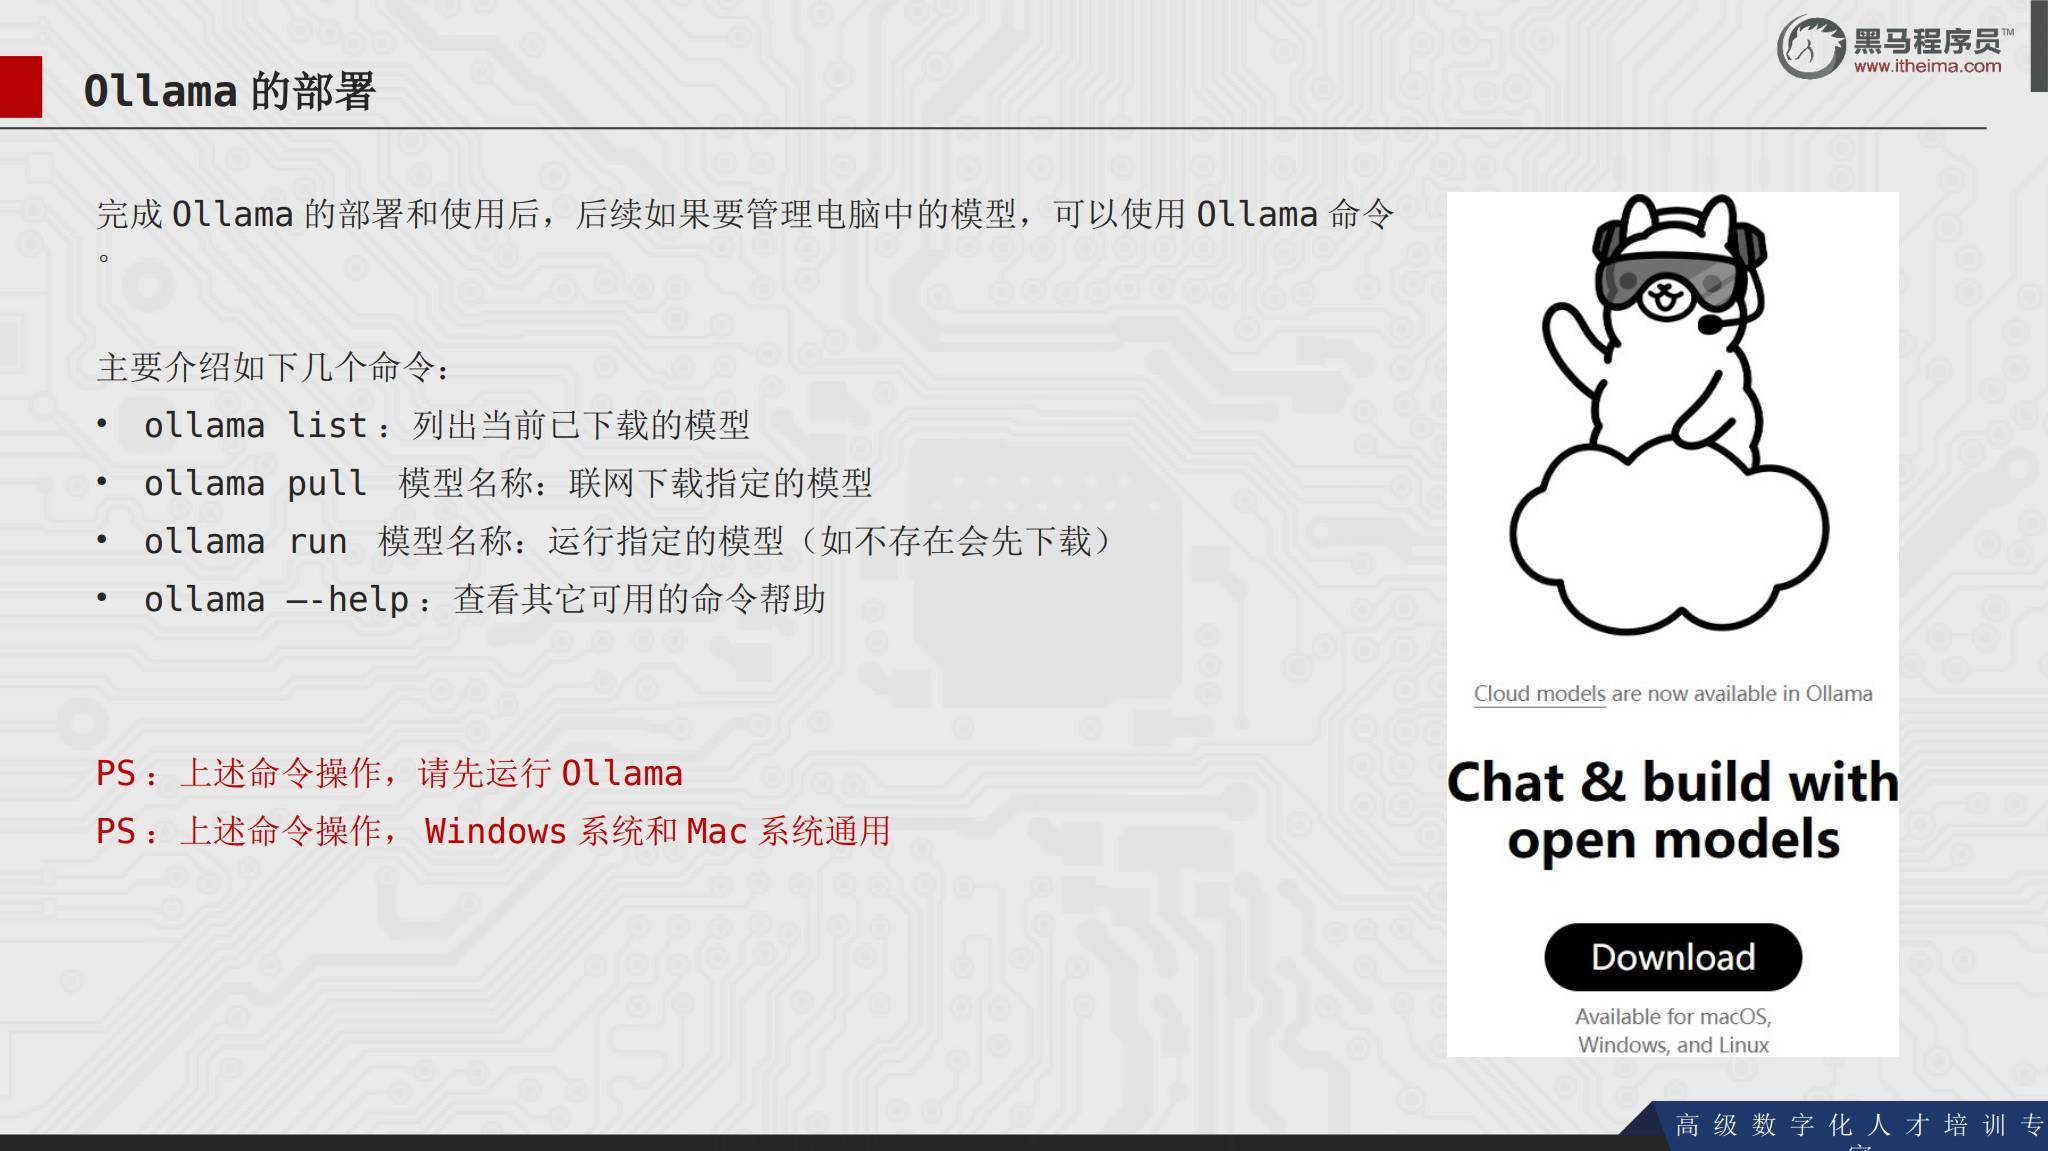


## 10. Ollama 模型库与参数规模

Ollama 官方模型库：<https://ollama.com/library>。

课件列出的模型包括 DeepSeek、Qwen、Llama、Phi-4、Mistral 等。选择模型时要关注参数规模和本地硬件：

- 参数量越大，通常需要更多内存或显存。
- 硬件能力不足时，模型运行和输出速度会下降。
- 课程将蒸馏模型解释为从标准大模型学习核心能力、但规模更小的模型。

课件给出的学习参考是：集成显卡可从约 `1.5B` 规模开始，4G 独显尝试 `8B` 以内，8G 独显尝试 `14B` 以内。实际可运行规模还与量化方式、上下文长度和其他进程有关，这些数值只作为课程中的起点。

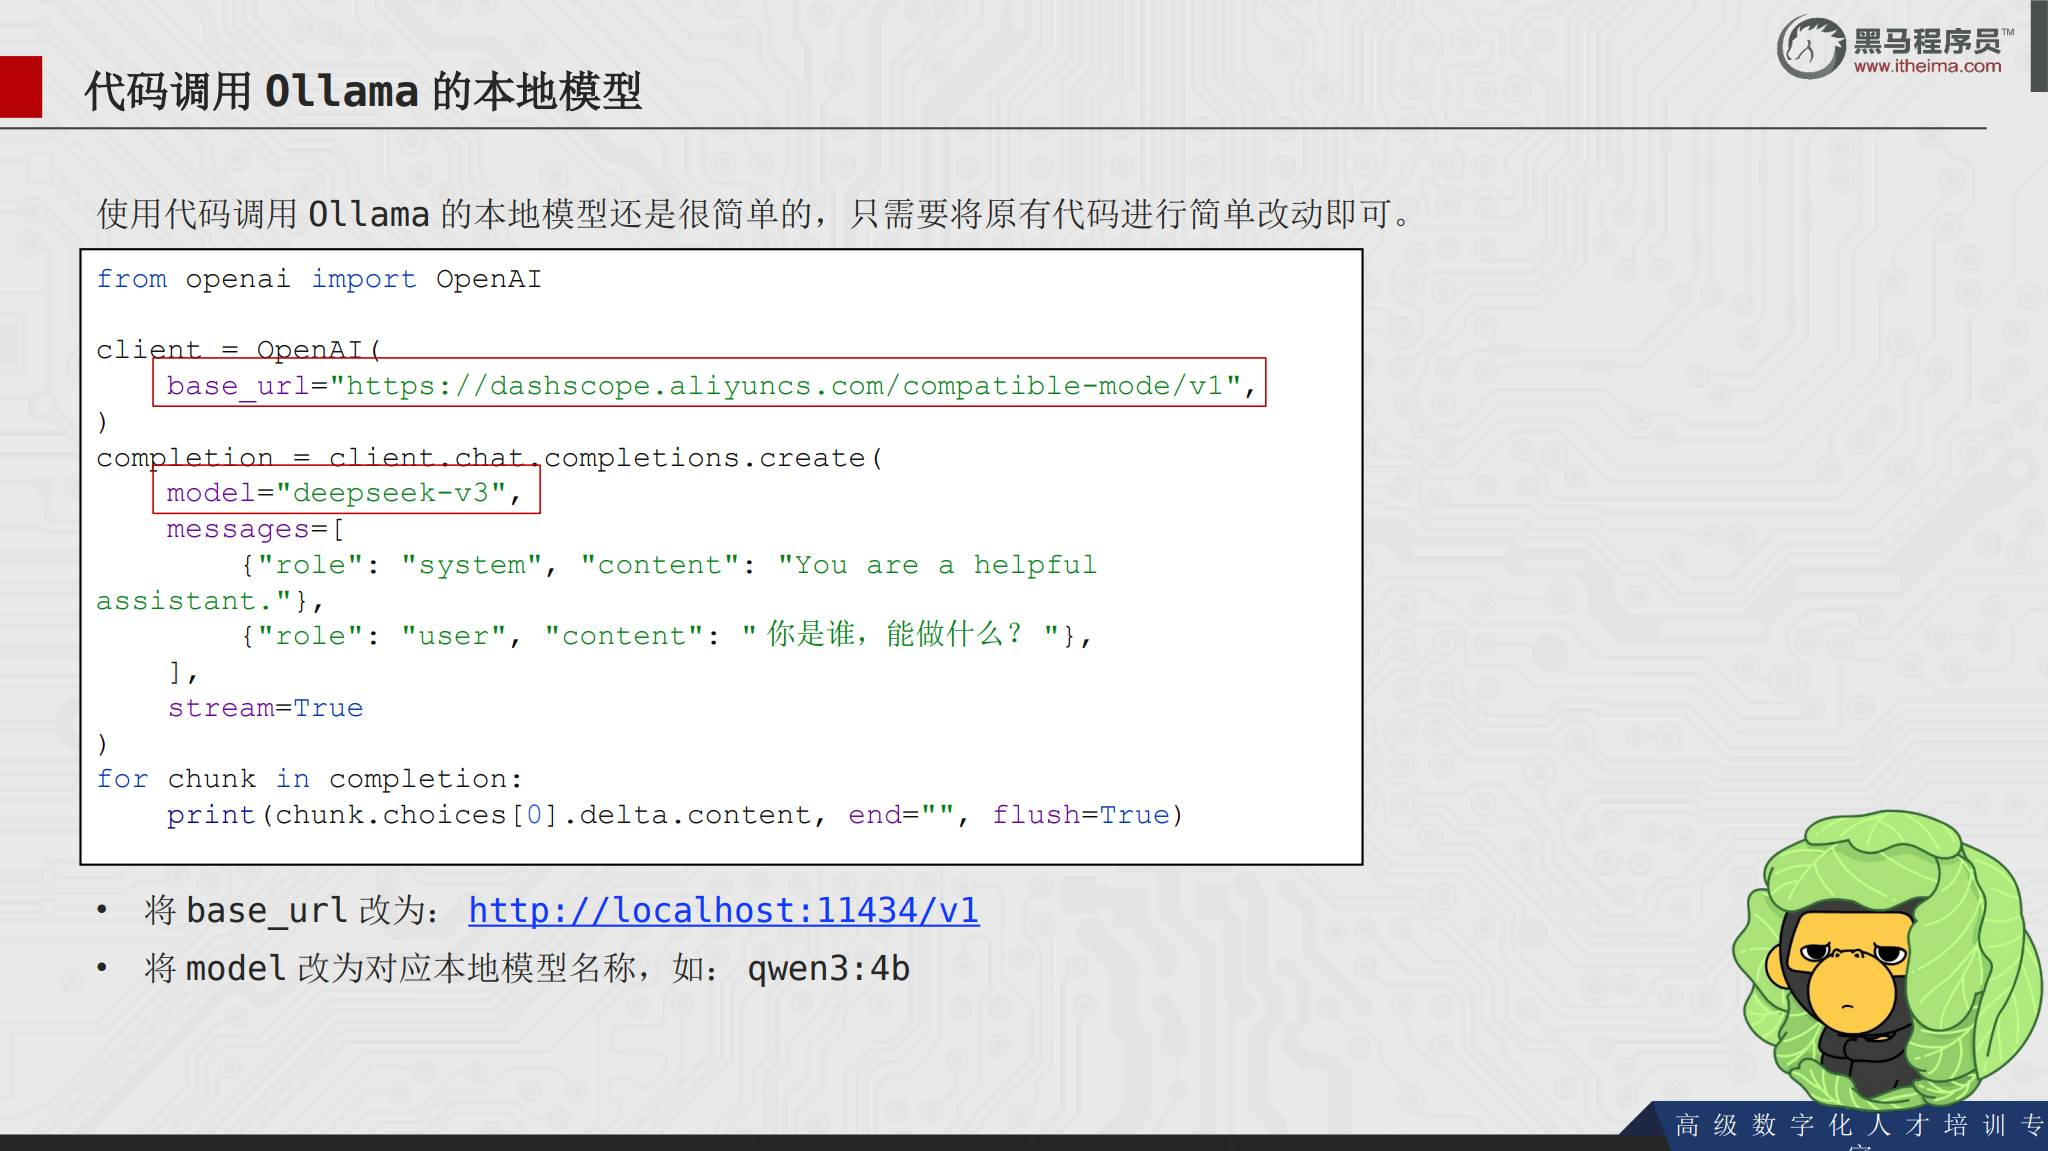


## 11. Windows 和 macOS 部署 Ollama

课程给出的部署方式是：进入 Ollama 官网，点击 Download，下载安装客户端。安装完成后，在命令行运行模型：

```bash
ollama run 模型名称
```

如果本地还没有该模型，`run` 通常会先下载，再进入命令行交互。首次下载需要等待模型文件完成，并确保磁盘空间足够。

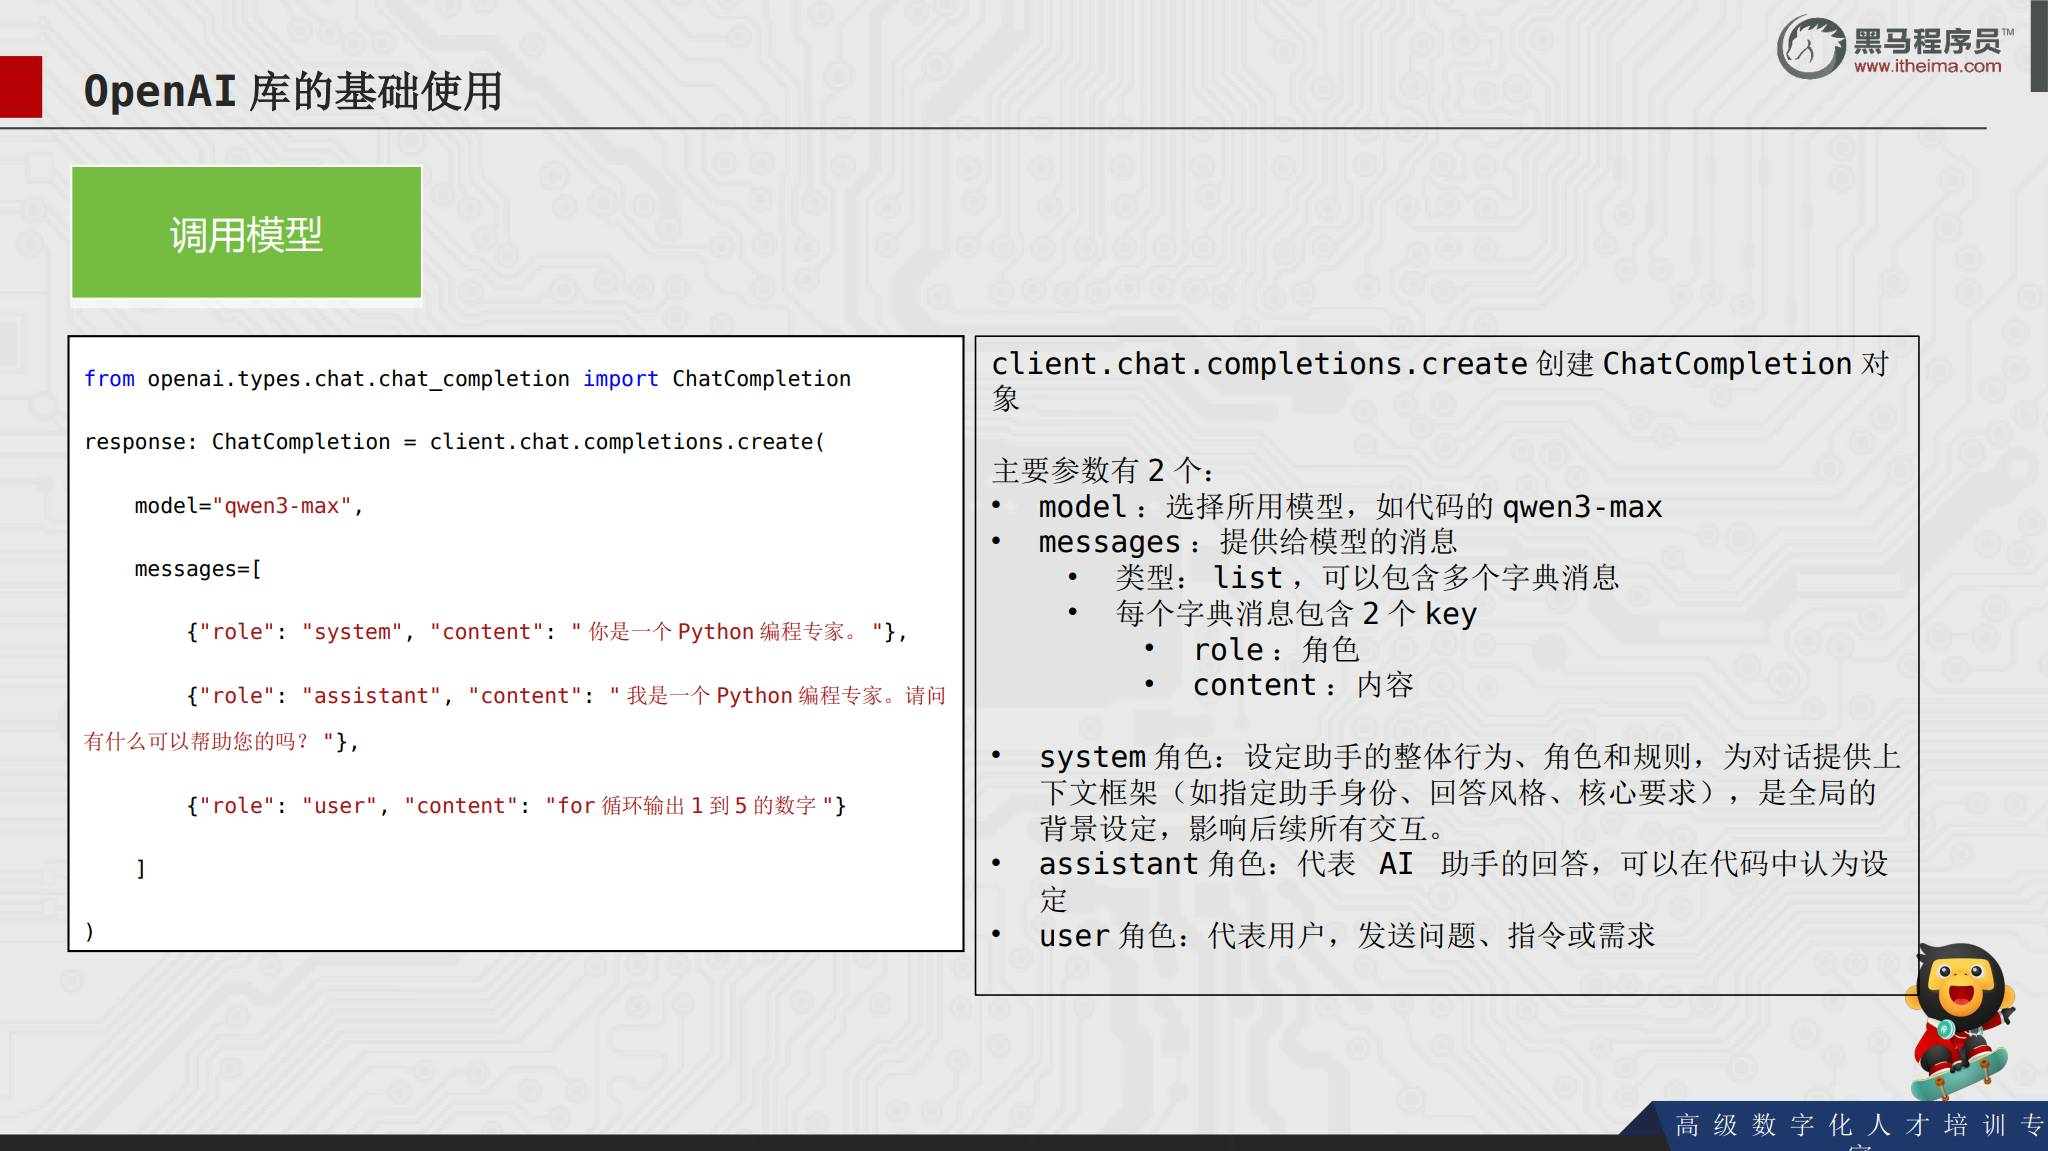


## 12. Ollama 常用命令

完成安装后，可以用命令管理本地模型：

```bash
ollama list                 # 列出已下载的模型
ollama pull 模型名称         # 联网下载指定模型
ollama run 模型名称          # 运行模型，不存在时先下载
ollama --help               # 查看其他命令
```

课件提醒，执行这些命令前先启动 Ollama；Windows 和 macOS 均可使用这组命令。


## 13. 用 OpenAI SDK 调用 Ollama

Ollama 提供兼容 OpenAI 风格的接口，课程给出的改动有两处：

1. 将 `base_url` 改为 `http://localhost:11434/v1`。
2. 将 `model` 改为本地已安装的模型名称，例如 `qwen3:4b`。

```python
from openai import OpenAI

client = OpenAI(
    base_url="http://localhost:11434/v1",
    api_key="ollama",  # 本地兼容接口通常需要一个占位值
)

response = client.chat.completions.create(
    model="qwen3:4b",
    messages=[
        {"role": "user", "content": "你是谁，能做什么？"},
    ],
)
print(response.choices[0].message.content)
```

核心思路是复用同一套 SDK 调用方式，只切换服务地址和模型名称。

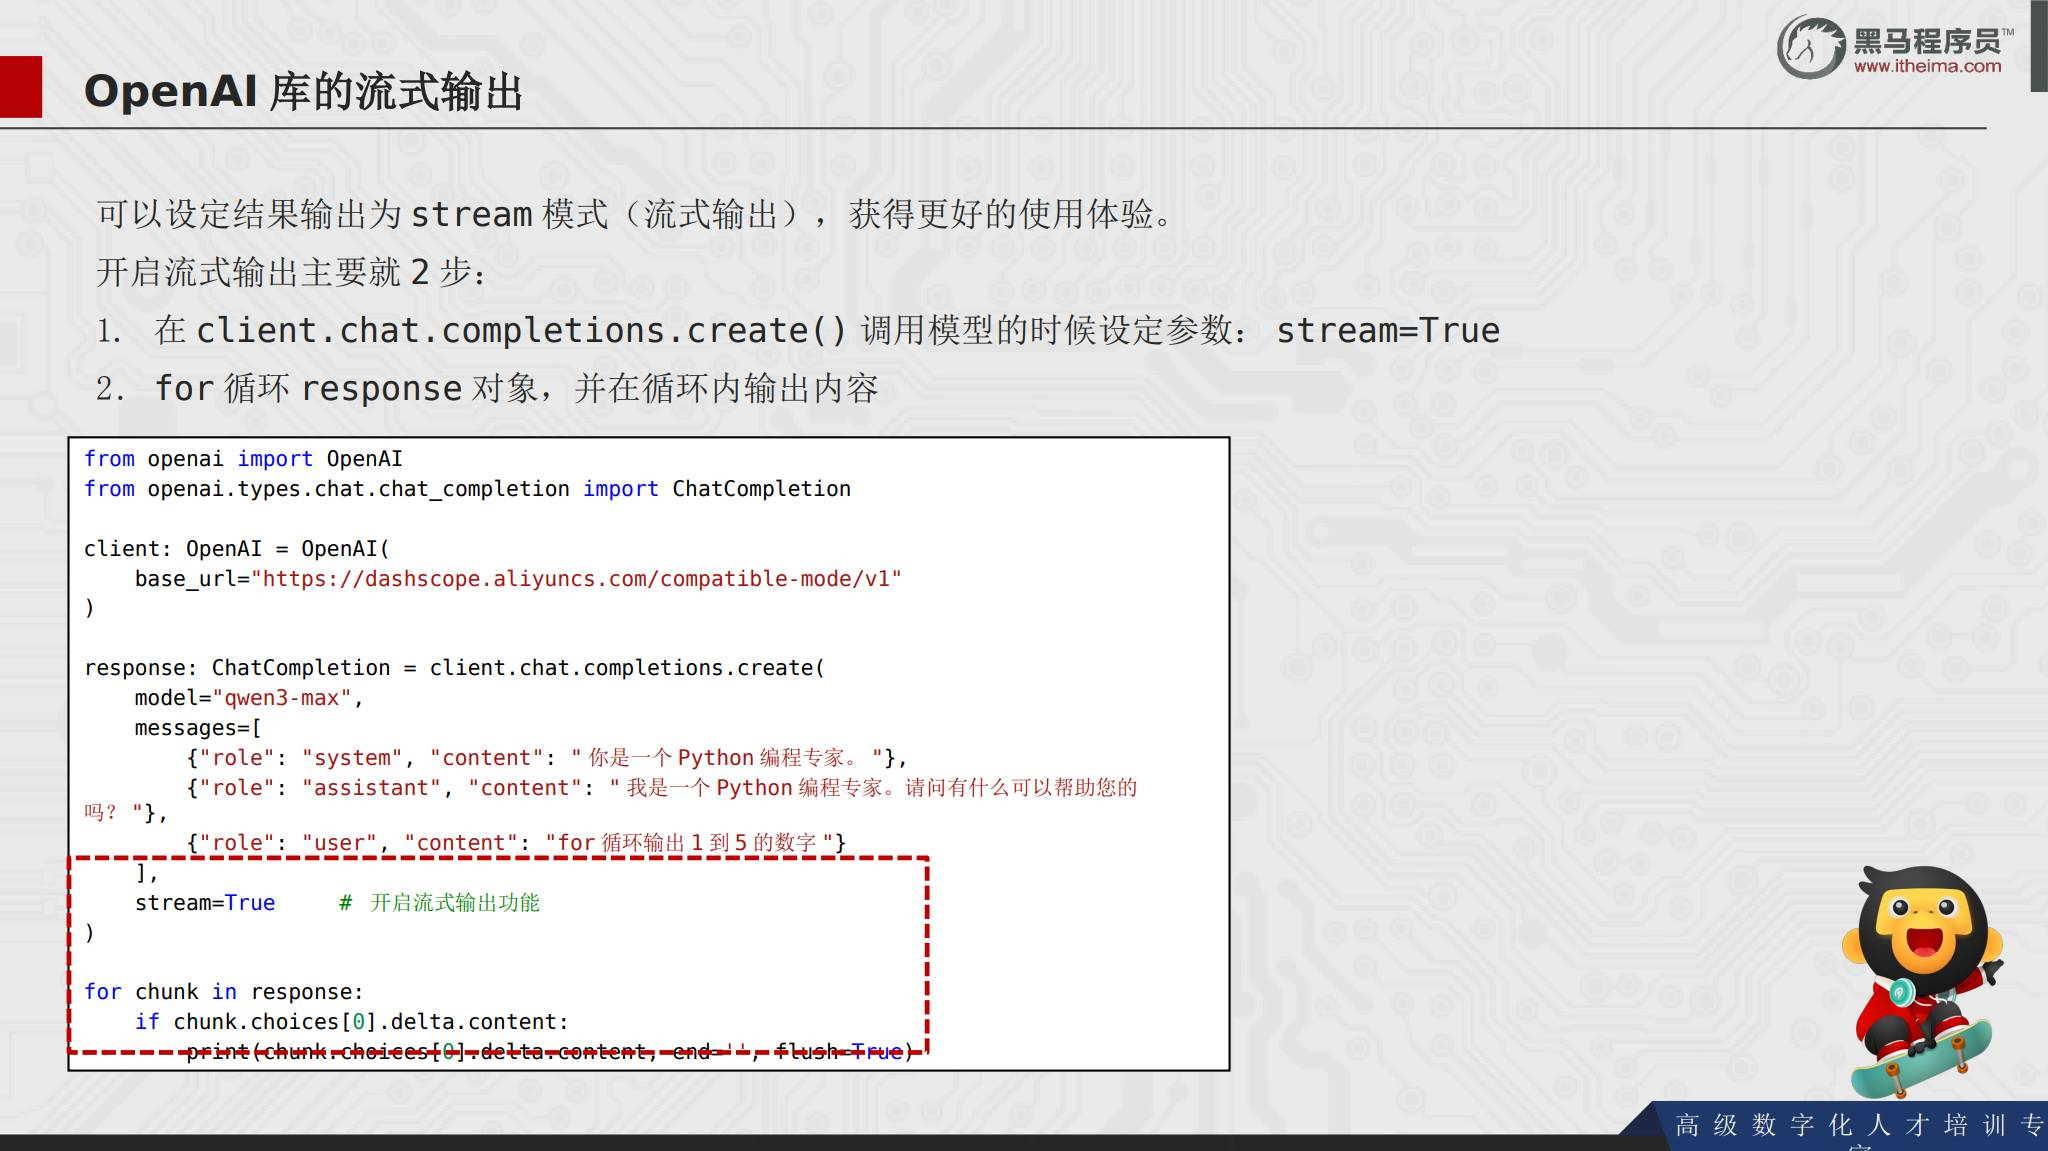


## 14. OpenAI 库的基本结构

OpenAI Python SDK 是 OpenAI 官方推出的 Python 客户端，负责封装 API 请求、身份验证等底层细节。由于接口设计通用，许多模型服务商提供 OpenAI 兼容接口，因此同一个 SDK 可以通过 `base_url` 切换服务商。

基础调用可以拆成三步：

1. 创建 `OpenAI` 客户端对象。
2. 调用 `client.chat.completions.create()` 与模型对话。
3. 从响应对象中读取模型结果。

客户端常用参数是 `api_key` 和 `base_url`。前者是服务商提供的密钥，后者是服务商的 API 接入地址。


## 15. `model` 与 `messages` 参数

`client.chat.completions.create()` 至少需要理解两个参数：

- `model`：选择模型，例如课件中的 `qwen3-max`。
- `messages`：提供对话消息的列表。

`messages` 中每条消息是包含 `role` 和 `content` 的字典。`system` 设定全局行为，`assistant` 表示助手历史回答，`user` 表示用户输入。

```python
response = client.chat.completions.create(
    model="qwen3-max",
    messages=[
        {"role": "system", "content": "你是一个 Python 编程专家。"},
        {"role": "assistant", "content": "我是一个 Python 编程专家。"},
        {"role": "user", "content": "for 循环输出 1 到 5 的数字。"},
    ],
)
```


## 16. 读取响应结果

非流式响应中，模型文本位于：

```python
print(response.choices[0].message.content)
```

这段代码从响应的第一个候选结果中取出消息内容。完整代码仍然遵循“客户端、模型调用、结果处理”三步。

流式模式则遍历 `response`，从每个 `chunk.choices[0].delta.content` 读取增量文本。


## 17. LLM 是什么

大语言模型（Large Language Model，LLM）是理解和生成人类语言的人工智能模型，可以处理文本分类、问答、翻译和对话等任务。

更基础的语言模型负责建模词汇序列的生成概率。给定词序列 `S = {W1, W2, ..., Wn}`，语言模型计算该序列发生的概率 `P(S)`；符合语言习惯的序列通常得到更高概率。

课程把语言模型技术的发展概括为四个阶段：

1. 基于规则和统计的语言模型。
2. 神经语言模型。
3. 预训练语言模型。
4. 大语言模型。


## 18. LLM 的三类架构

LLM 通常建立在 Transformer 架构之上，按使用编码器和解码器的方式，课程分为三类：

| 类型 | 结构 | 基本方式 | 代表模型 | 常见任务 |
| --- | --- | --- | --- | --- |
| 自编码模型（AE） | Encoder-only | 随机遮住部分词，根据上下文预测 | BERT | 分类、情感分析、抽取式问答 |
| 自回归模型（AR） | Decoder-only | 从左到右，根据前文预测下一个时间步 | GPT | 摘要、翻译、文本生成 |
| 序列到序列模型 | Encoder-decoder | 编码输入，再生成目标序列 | T5 | 机器翻译、文本到文本转换 |

这些是课件中的架构分类，实际模型可能结合更复杂的训练目标和工程优化。


## 19. 主流模型与规模概览

课件介绍了 LLaMA、ChatGLM、Qwen 和 DeepSeek 等模型系列：

- **LLaMA**：Meta AI 发布，课件强调其早期训练数据以英语和代码为主。
- **ChatGLM**：清华提出的开源中英双语对话模型系列。
- **Qwen**：阿里云通义千问系列，覆盖自然语言和多模态场景；课件提到 RoPE、RMSNorm、SwiGLU 等设计。
- **DeepSeek**：深度求索开发的模型系列，课件提到 Transformer、MoE 和 MLA 等技术路线。

课件还用 7B、13B、32B、70B、304B 等参数规模对训练显存、推理显存、CPU 内存、训练时间和 GPU 数量做了量级对比。这里的表格是课程时期的部署参考，模型版本、量化方式和硬件需求会随实现变化，不应当当作固定规格。

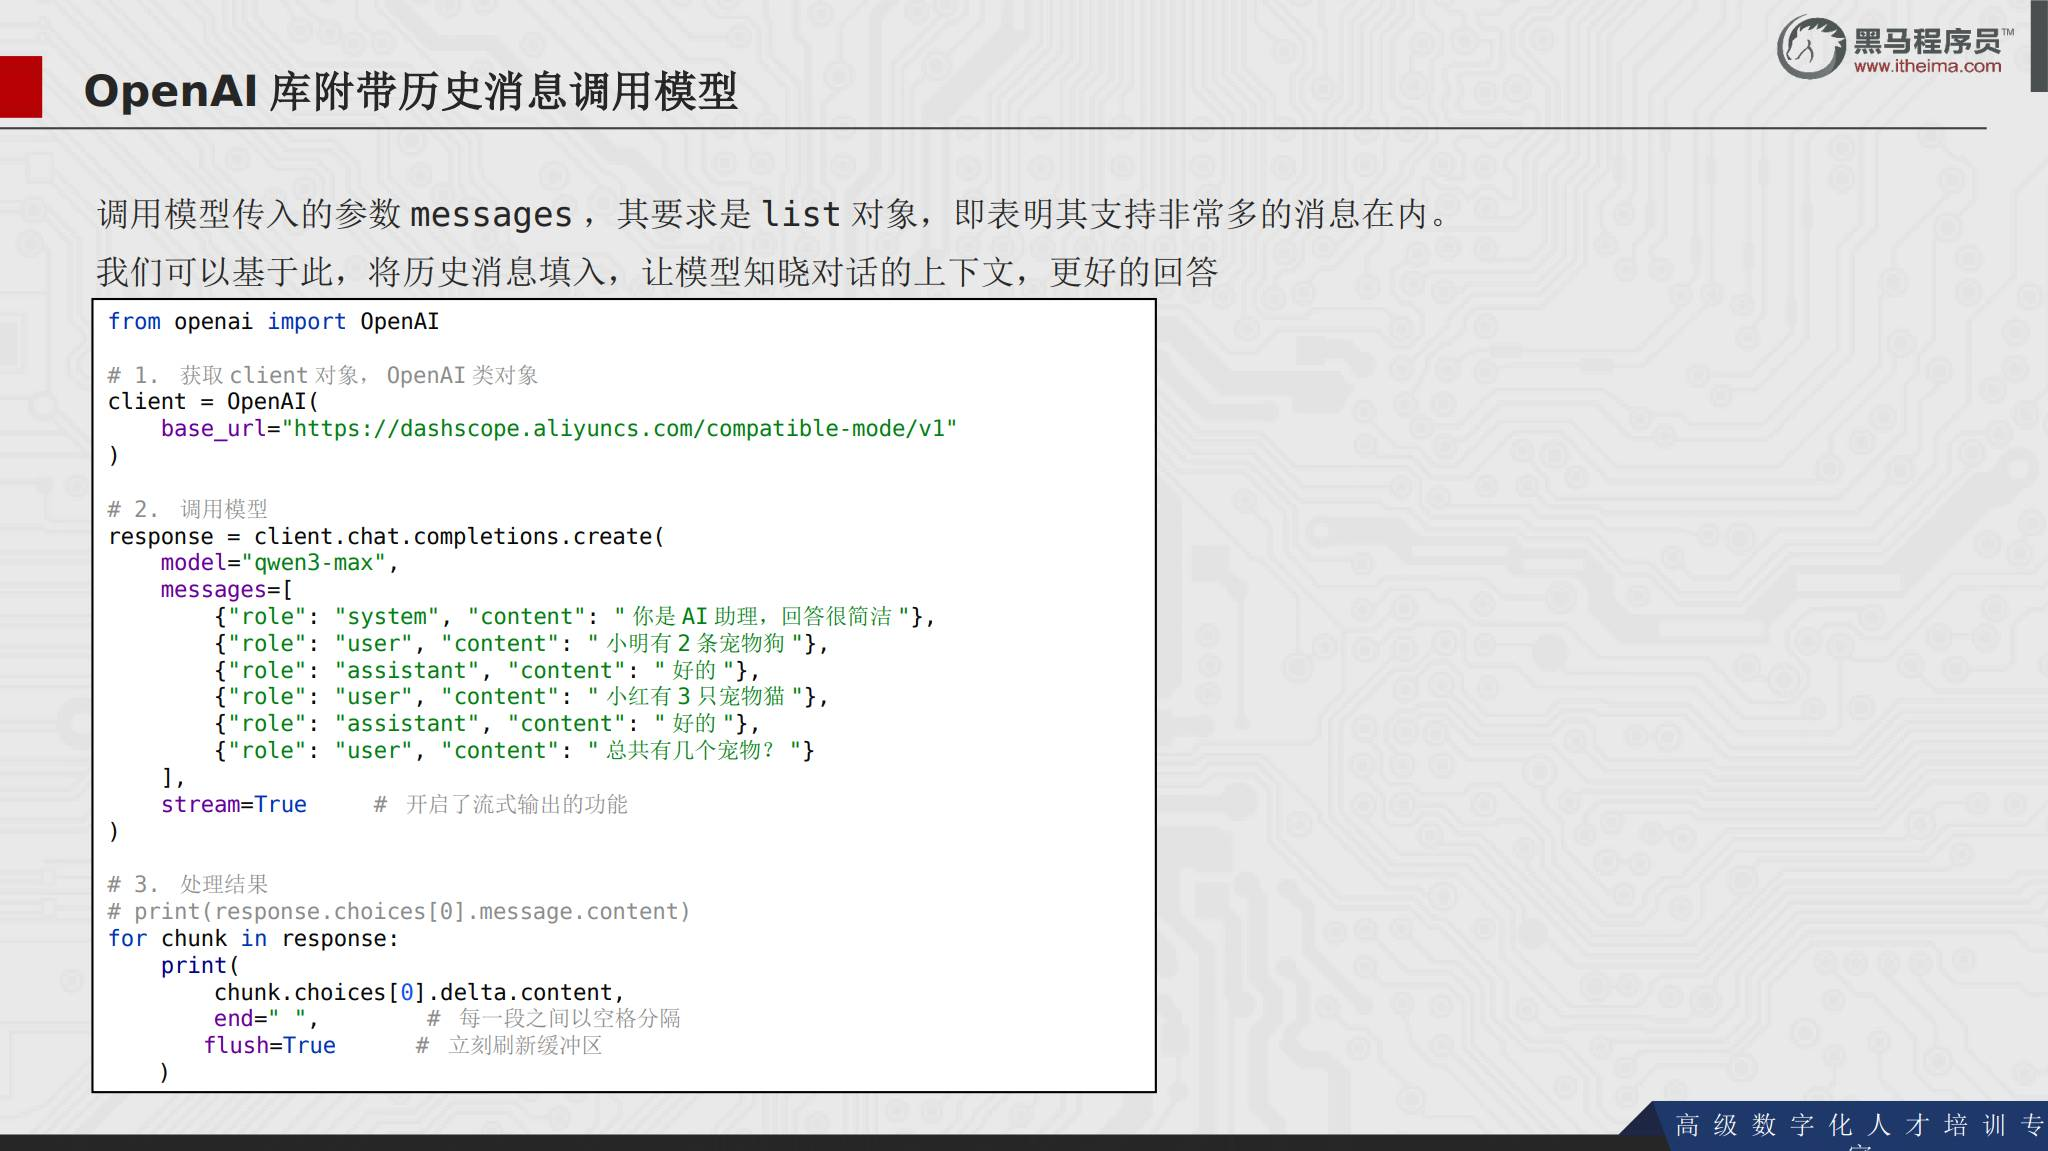


## 20. 什么是提示词工程

提示词工程（Prompt Engineering，也称 In-Context Prompting）是在不更新模型权重的情况下，通过设计输入来引导模型行为、获得期望结果的方法。

提示词可以是“讲个笑话”、 “用 Python 编写一个贪吃蛇游戏”或一组带有规则和示例的复杂任务说明。模型输出质量很大程度上取决于任务是否说清楚。

提示词工程是大模型应用开发的基础。RAG、Agent 和其他围绕模型的开发工作，最终都需要把任务、上下文和约束组织成模型能够理解的输入。

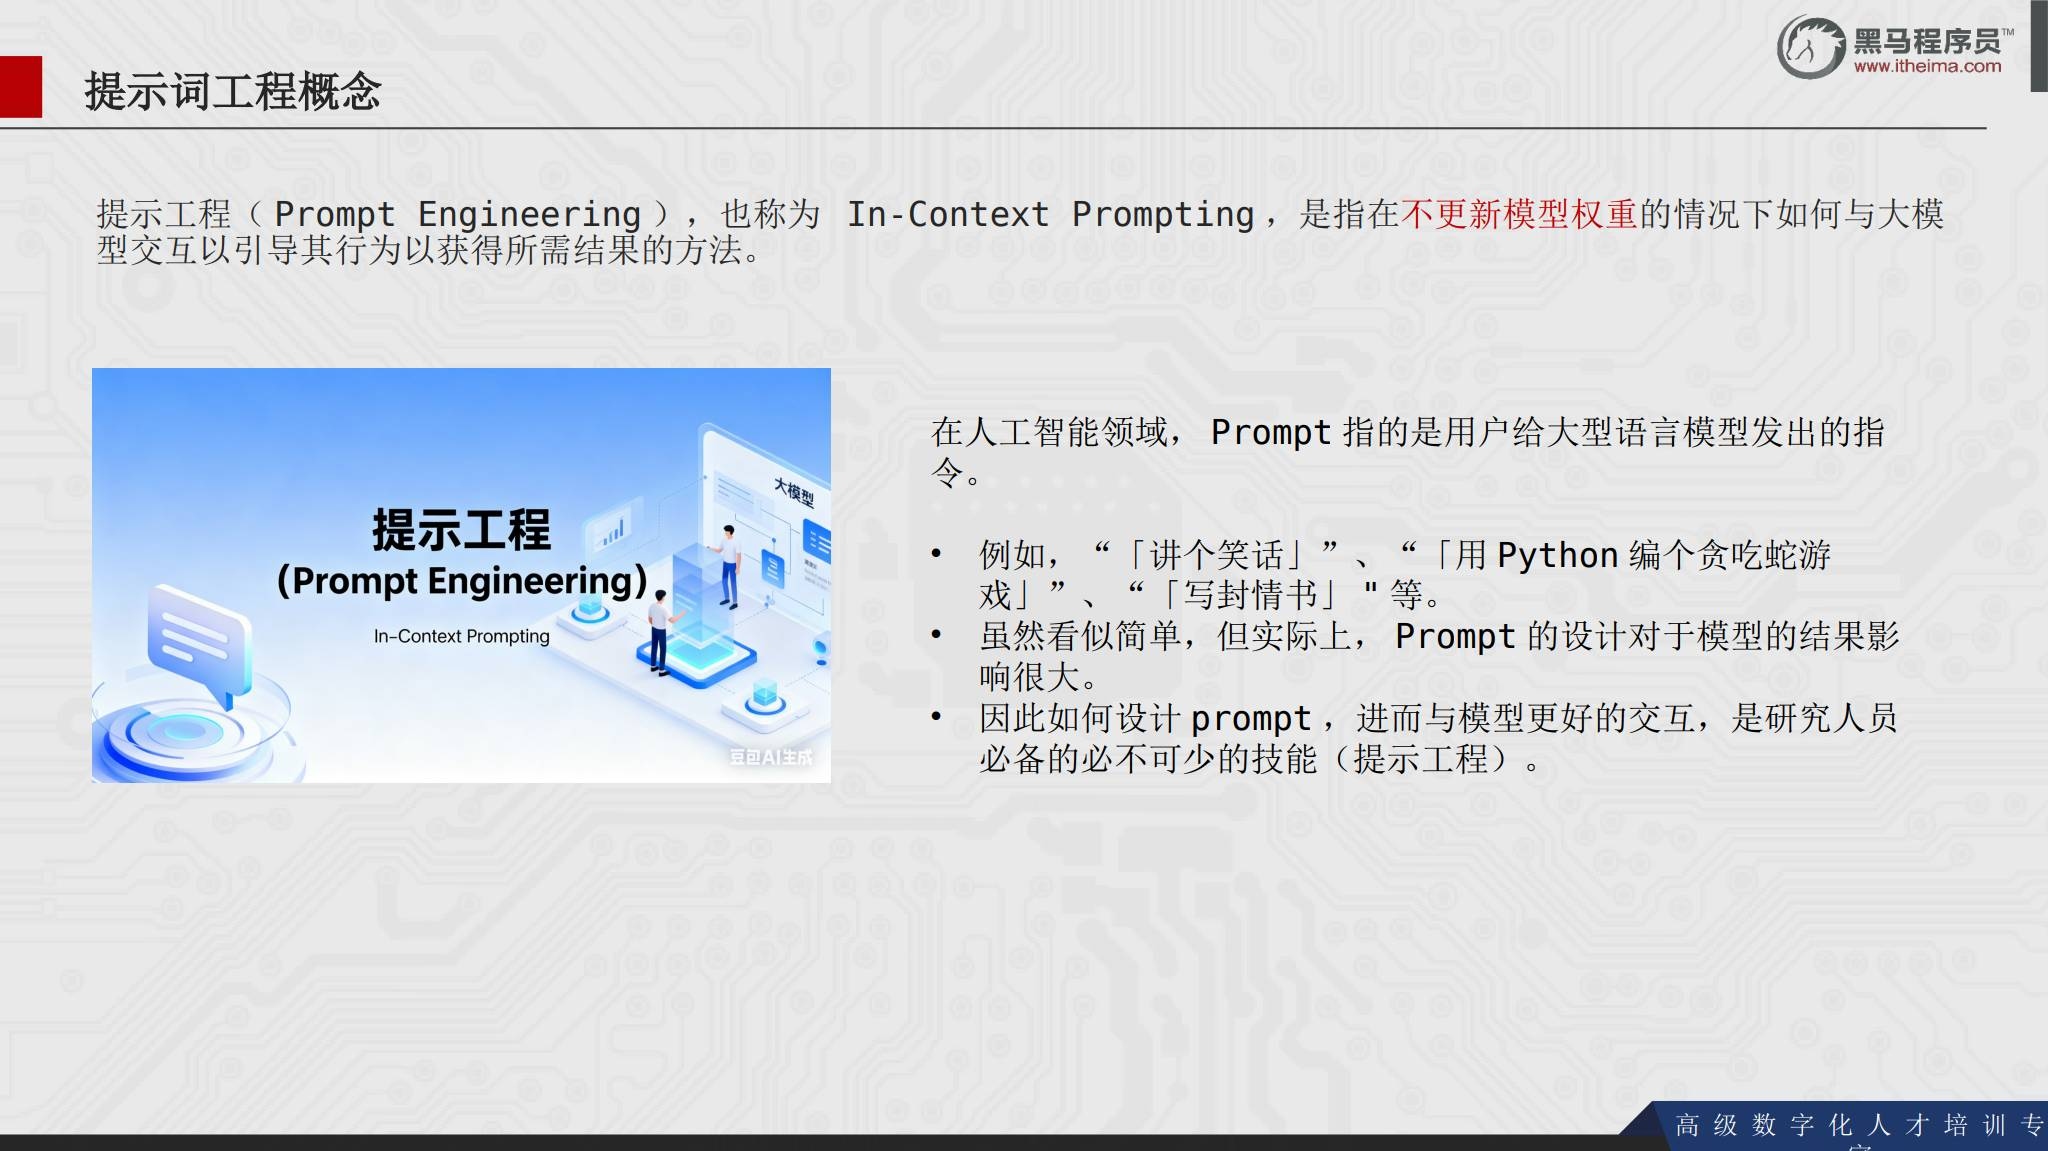


## 21. 六种常用提示词技巧

课程强调，任何技巧都不能替代清晰表达。课件给出的技巧包括：

1. **详细描述**：说明任务目标、语气、长度和限制，而不是只说“写一封情书”。
2. **指定角色**：让模型充当 AI 算法面试官等角色，规定交互节奏和职责。
3. **使用分隔符**：用三引号、XML 标签或中括号区分指令和输入文本。
4. **指定步骤**：把复杂任务拆开，例如先总结，再翻译，并给每一步规定前缀。
5. **提供例子**：先给输入与输出示例，让模型参照格式生成新样本。
6. **使用参考文档**：要求模型只依据给定文本回答，找不到答案时明确说明，不自行编造。

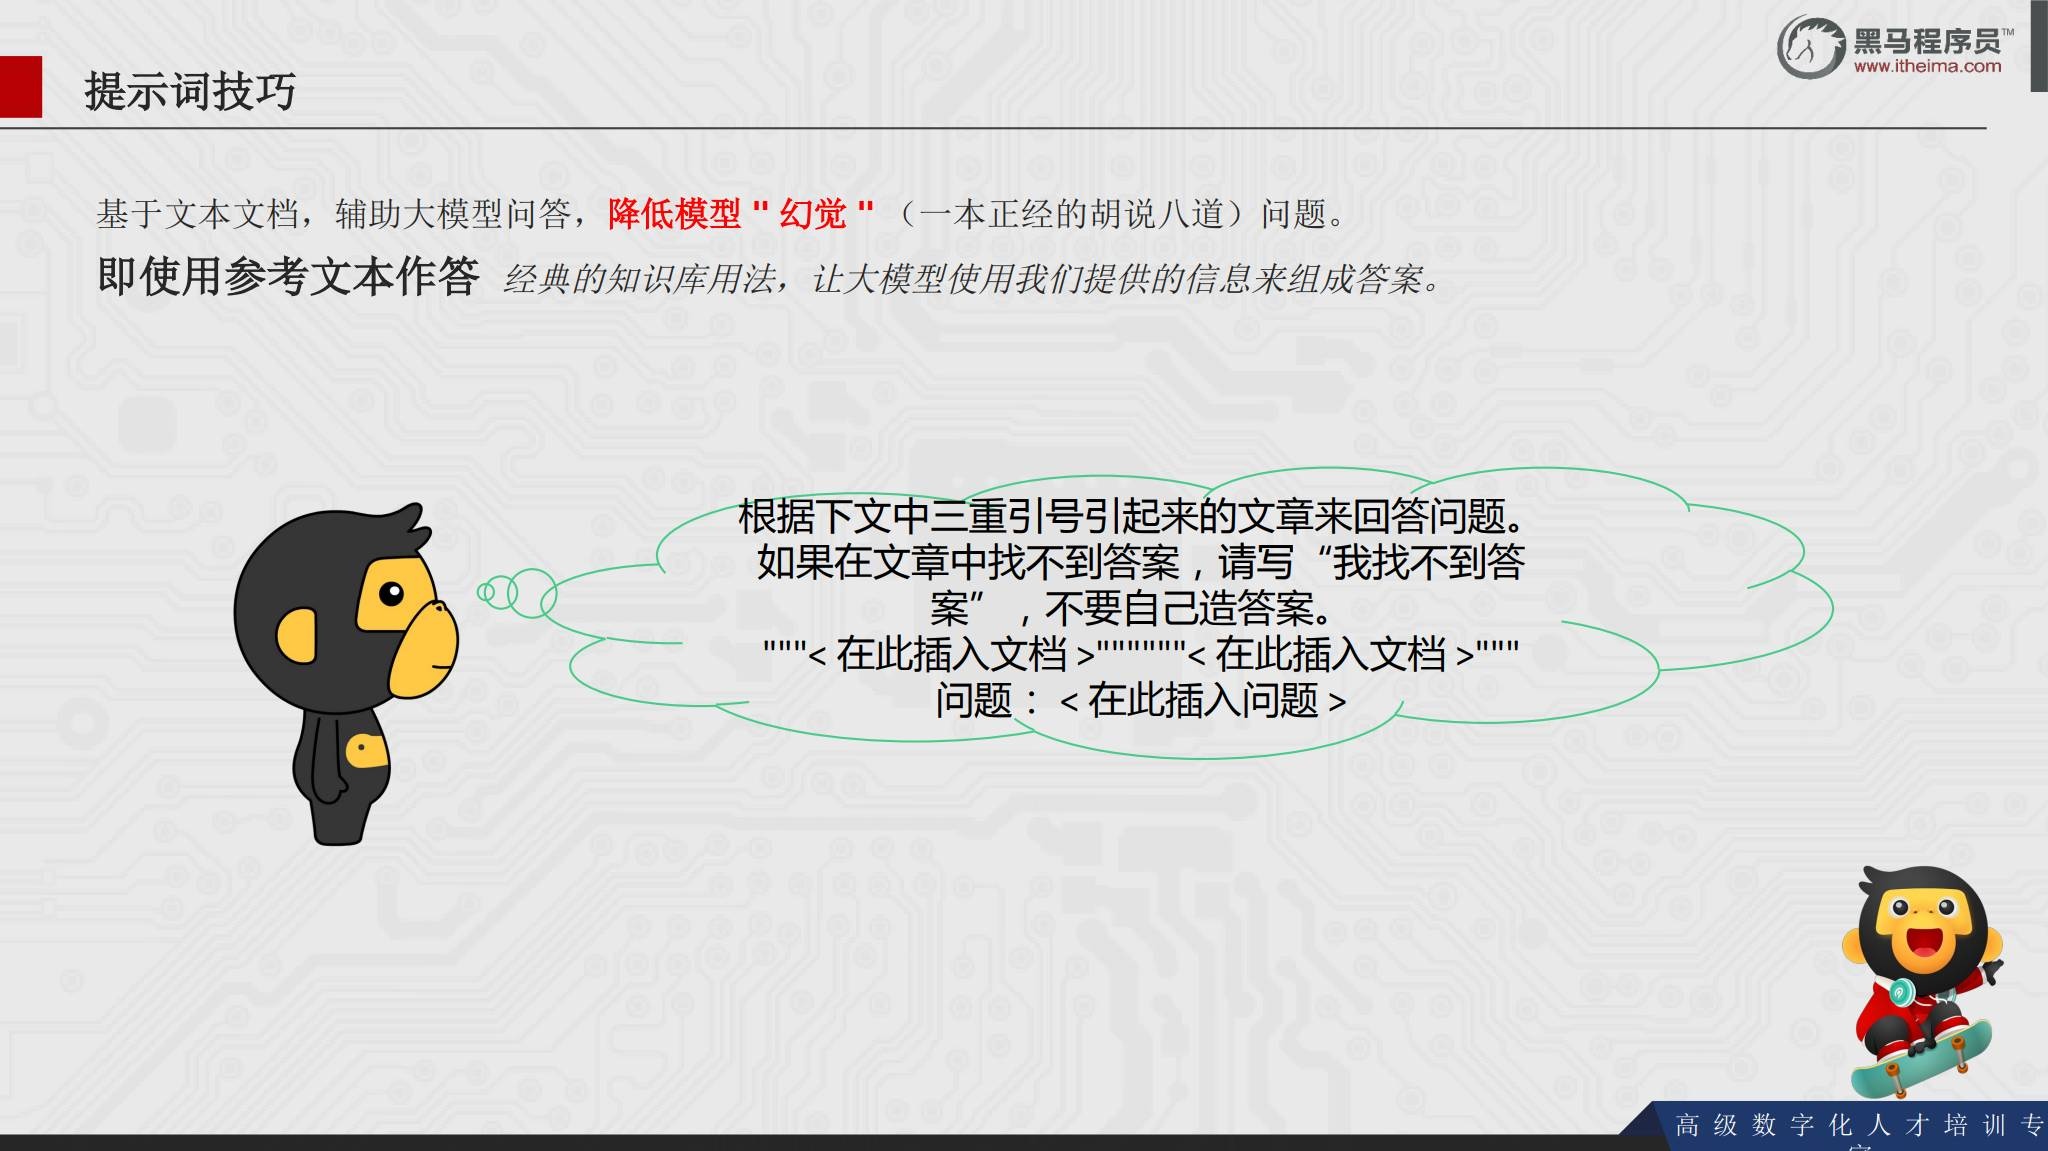


## 22. Zero-shot 与 Few-shot

### Zero-shot

Zero-shot 是不提供示例，只用语言描述任务、目标和约束，让模型利用预训练能力直接完成任务。例如：让模型判断三引号内评论的情感倾向，只输出“正面”或“负面”。

### Few-shot

Few-shot 是提供少量输入与期望输出示例，让模型参考示例理解任务和输出格式。例如，先给出两个“产品名称 + 产品卖点”的 JSON 示例，再要求模型处理新的产品描述。

| 方法 | 提示词中包含什么 | 主要价值 |
| --- | --- | --- |
| Zero-shot | 任务描述、目标和约束 | 简洁，直接利用模型已有能力 |
| Few-shot | 任务描述加少量示例 | 提高格式和任务边界的对齐程度 |

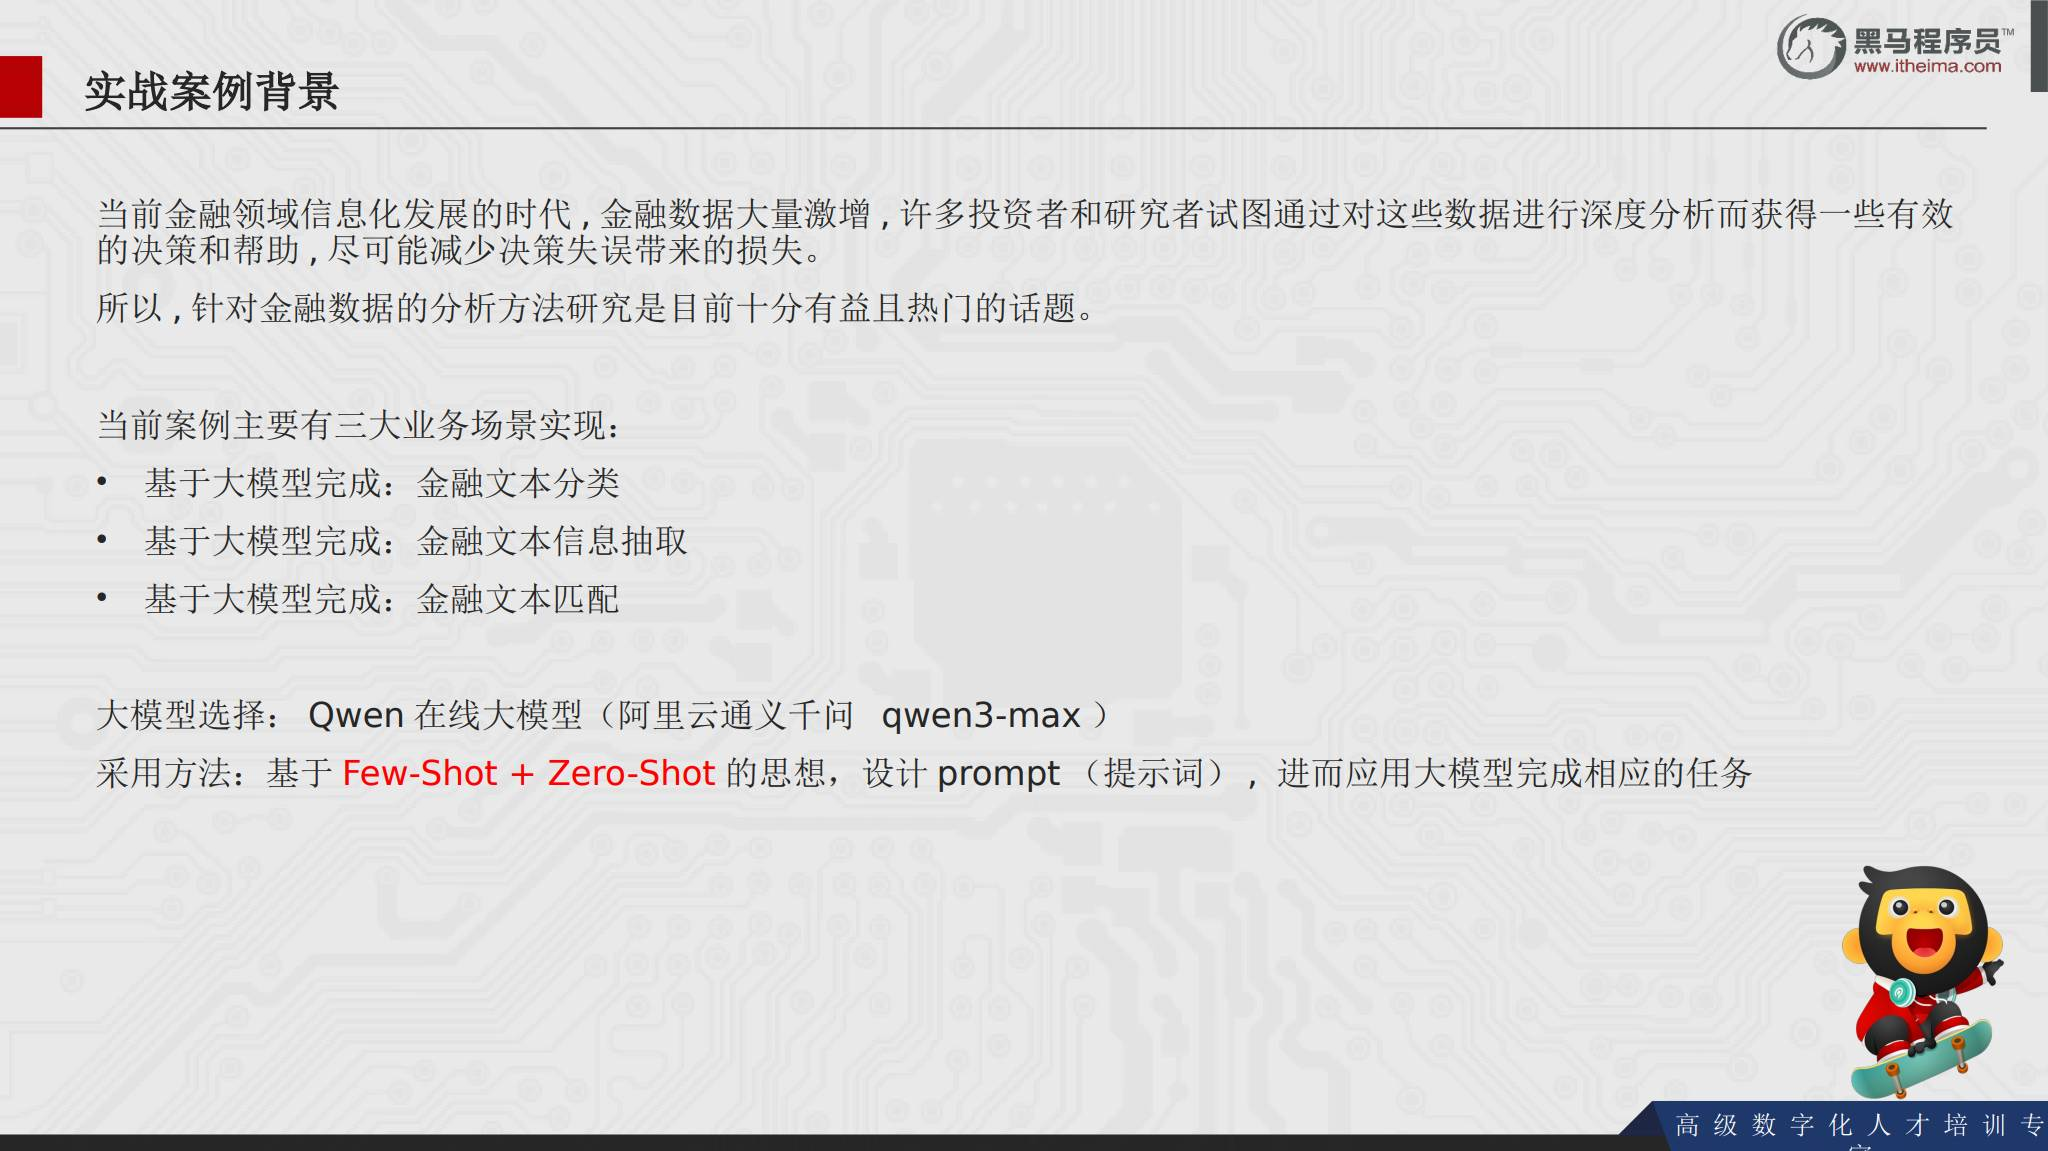

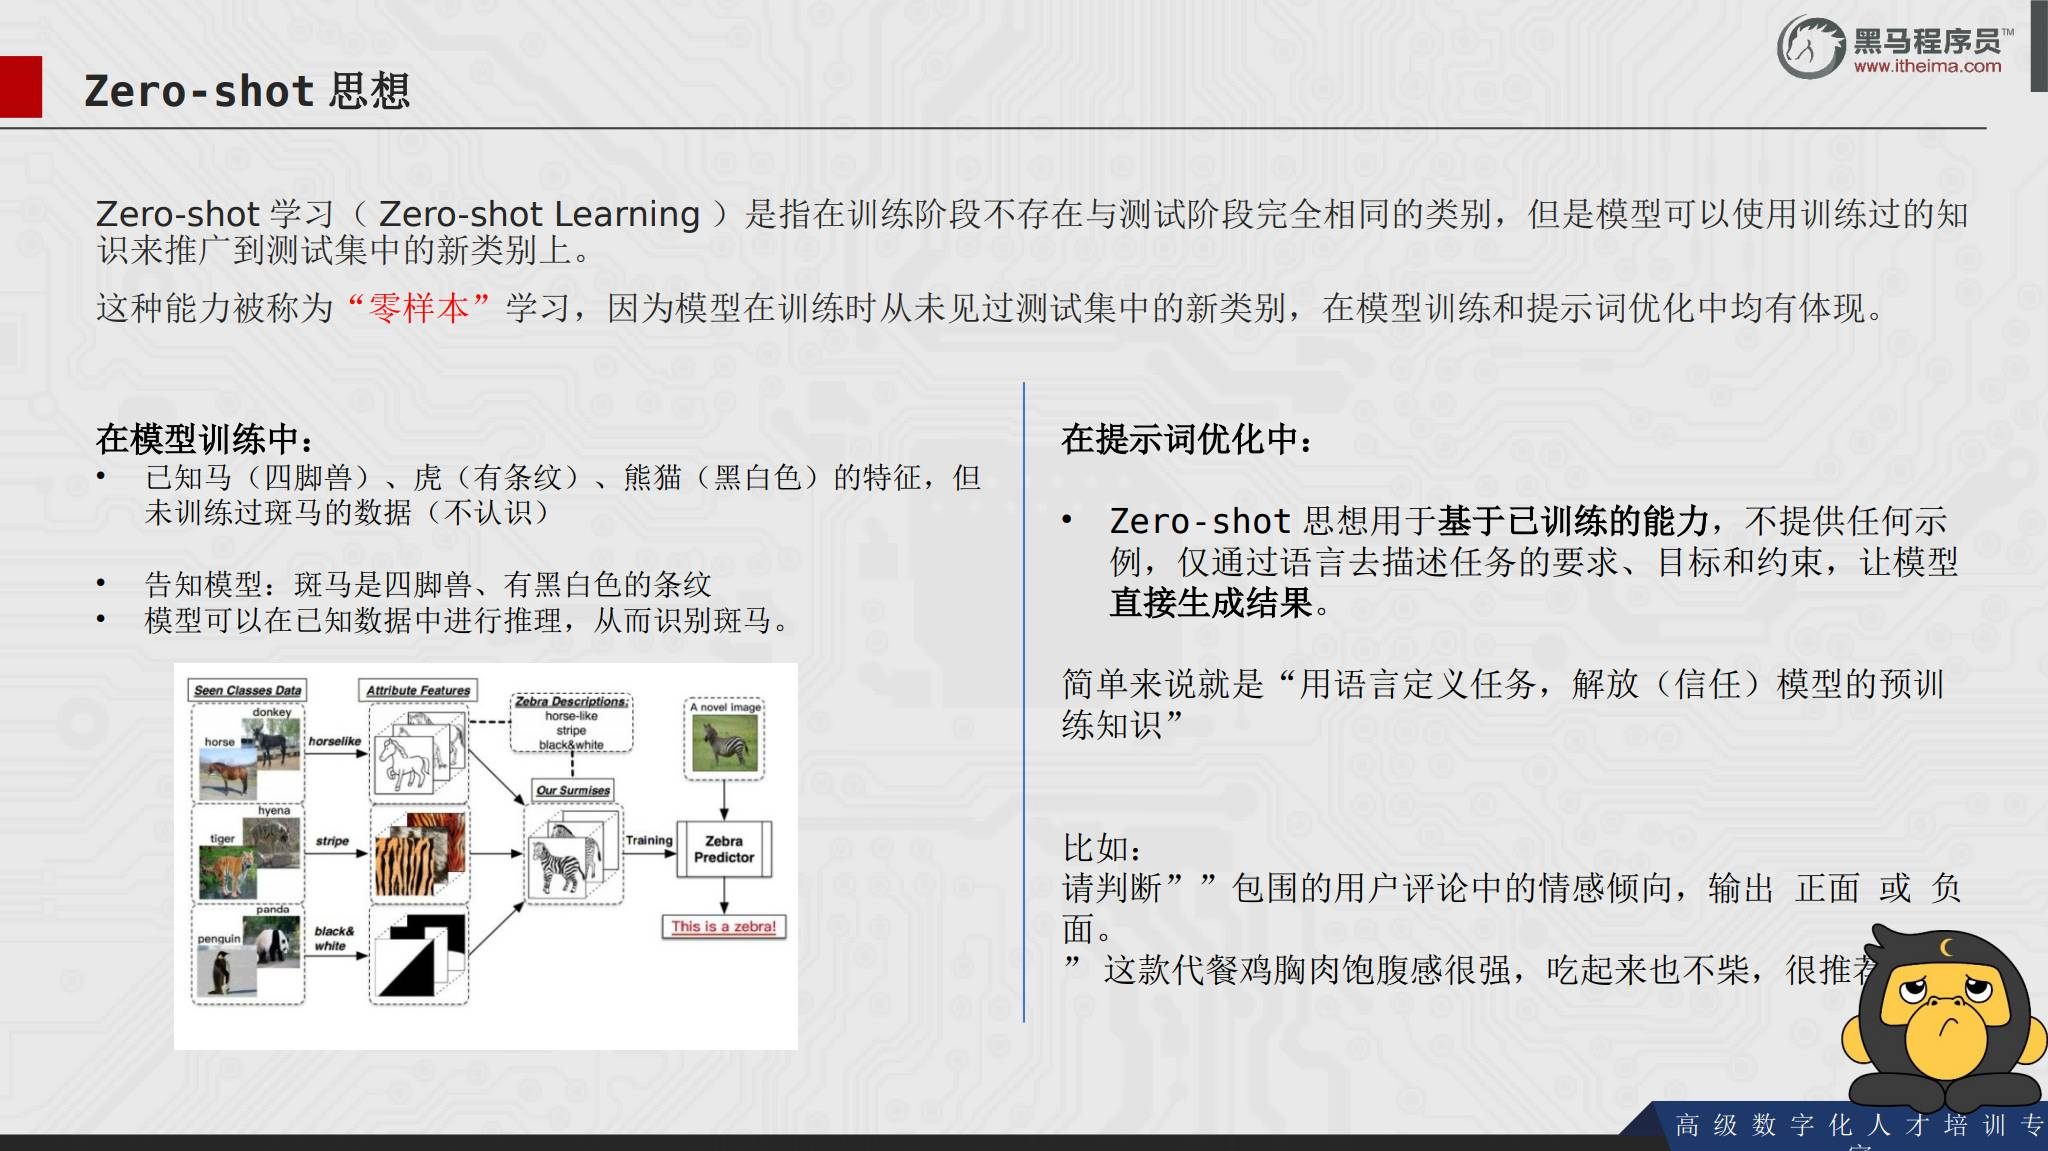


## 23. 金融文本实战的三个任务

课程用 Qwen 在线模型完成三个金融领域任务：

1. **金融文本分类**：识别文本属于新闻报道、公司公告、财务报告或分析师报告。
2. **金融文本信息抽取**：从股票文本中提取日期、股票名称、开盘价、收盘价和成交量等字段。
3. **金融文本匹配**：判断两句话的语义是否相关，只输出“是”或“不是”。

三个任务都使用 Zero-shot 或 Few-shot 思想设计 Prompt；区别在于分类关注标签，抽取关注结构化字段，匹配关注语义关系。

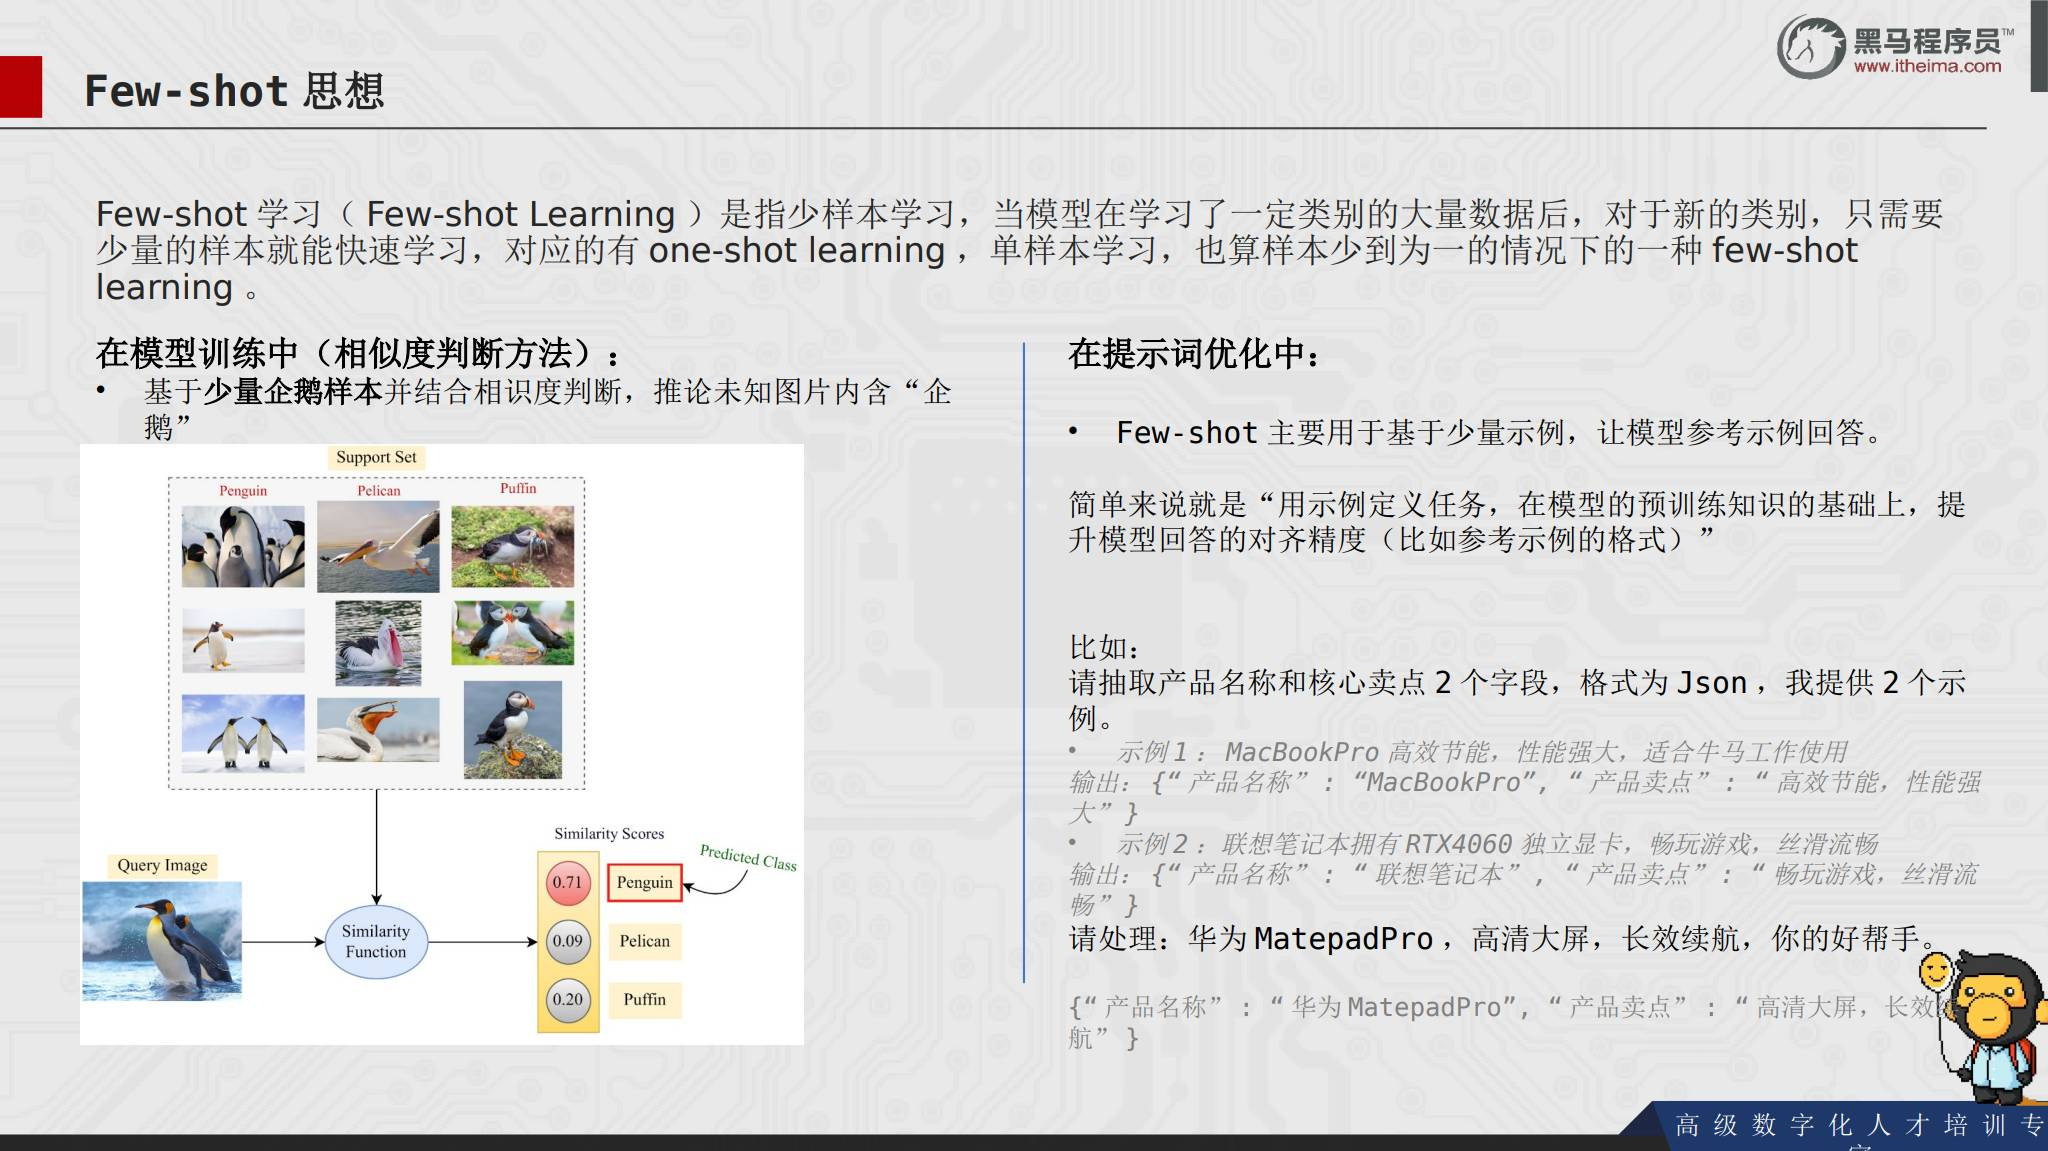


## 24. 金融文本分类：先明确标签

课件给出的分类标签是：

- 新闻报道
- 公司公告
- 财务报告
- 分析师报告

任务需要模型判断文本属于哪一类。示例中，央行降息消息属于新闻报道，公司收购公告属于公司公告，资产负债表描述属于财务报告，行业趋势分析属于分析师报告。

不属于这四类的文本，课件在示例代码中要求输出“**不清楚类型**”。这条兜底规则可以避免模型把无关文本硬塞进某个金融类别。

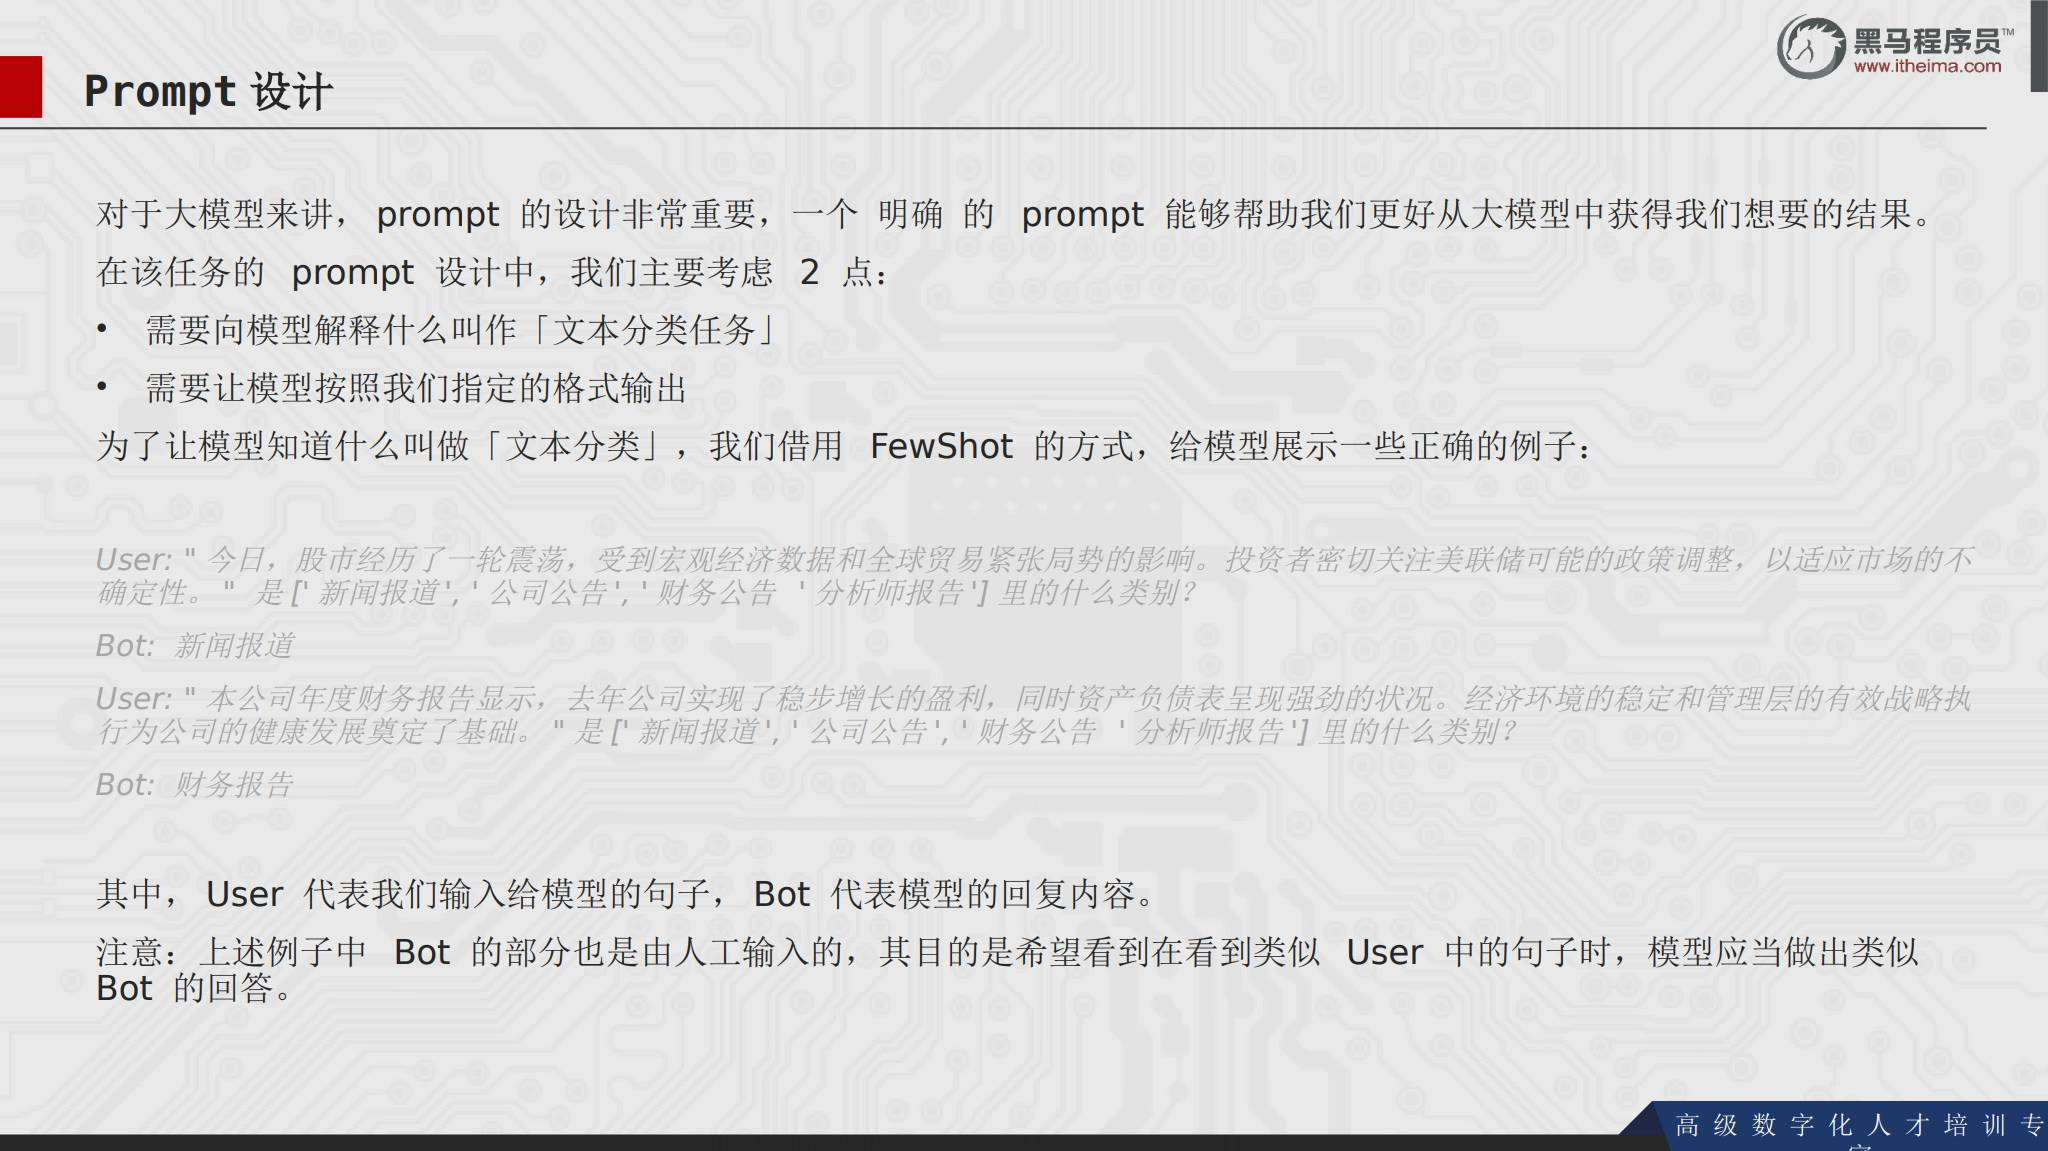


## 25. 金融文本分类的 Few-shot Prompt

分类 Prompt 需要同时说明任务和输出格式，并用示例让模型知道类别边界：

```text
你是一个金融专家。请把输入文本归类到：
新闻报道、财务报告、公司公告、分析师报告。
如果不属于这四类，输出“不清楚类型”。只输出类别名称。

示例：
用户：今日股市经历震荡，投资者关注政策调整。
助手：新闻报道

示例：本公司年度财务报告显示盈利稳步增长。
助手：财务报告

待分类文本：{text}
```

对应代码通常把示例整理成 `messages` 历史消息，再把待分类文本追加为最后一条 `user` 消息。


## 26. 分类任务代码结构

课件把分类脚本拆成两个核心函数：`init_prompt()` 和 `qwen_model()`。

```python
def init_prompt(examples):
    history = [{
        "role": "system",
        "content": (
            "你是金融专家，把文本归类到指定类别；"
            "不属于类别时输出‘不清楚类型’。"
        ),
    }]
    for label, example_text in examples.items():
        history.append({"role": "user", "content": example_text})
        history.append({"role": "assistant", "content": label})
    return history


def qwen_model(prompt, client, history):
    response = client.chat.completions.create(
        model=os.getenv("MODEL"),
        messages=history + [{"role": "user", "content": prompt}],
    )
    return response.choices[0].message.content
```

运行时先用示例初始化历史消息，再遍历待分类文本调用模型。课件的测试数据还包含一句无关文本，用来验证“不清楚类型”的兜底分支。


## 27. JSON 数据格式

JSON（JavaScript Object Notation）是一种轻量级的数据交换格式，便于人阅读，也便于程序解析和生成。与普通文本相比，JSON 更适合表达结构化抽取结果。

JSON 有两种基本结构：

- **JSON 对象**：用大括号表示，对应 Python 字典。
- **JSON 数组**：用方括号表示，通常包含多个对象，对应 Python 列表。

```json
{
  "age": 11,
  "name": "示例",
  "hobby": ["阅读", "编程"],
  "other": {"身高": 172, "体重": 68}
}
```

在 Python 中使用内置 `json` 库：

```python
import json

text = json.dumps(data, ensure_ascii=False)
data = json.loads(text)
```

`json.dumps()` 把字典或列表转换成 JSON 字符串，`ensure_ascii=False` 让中文正常显示；`json.loads()` 把 JSON 字符串转换回 Python 字典或列表。

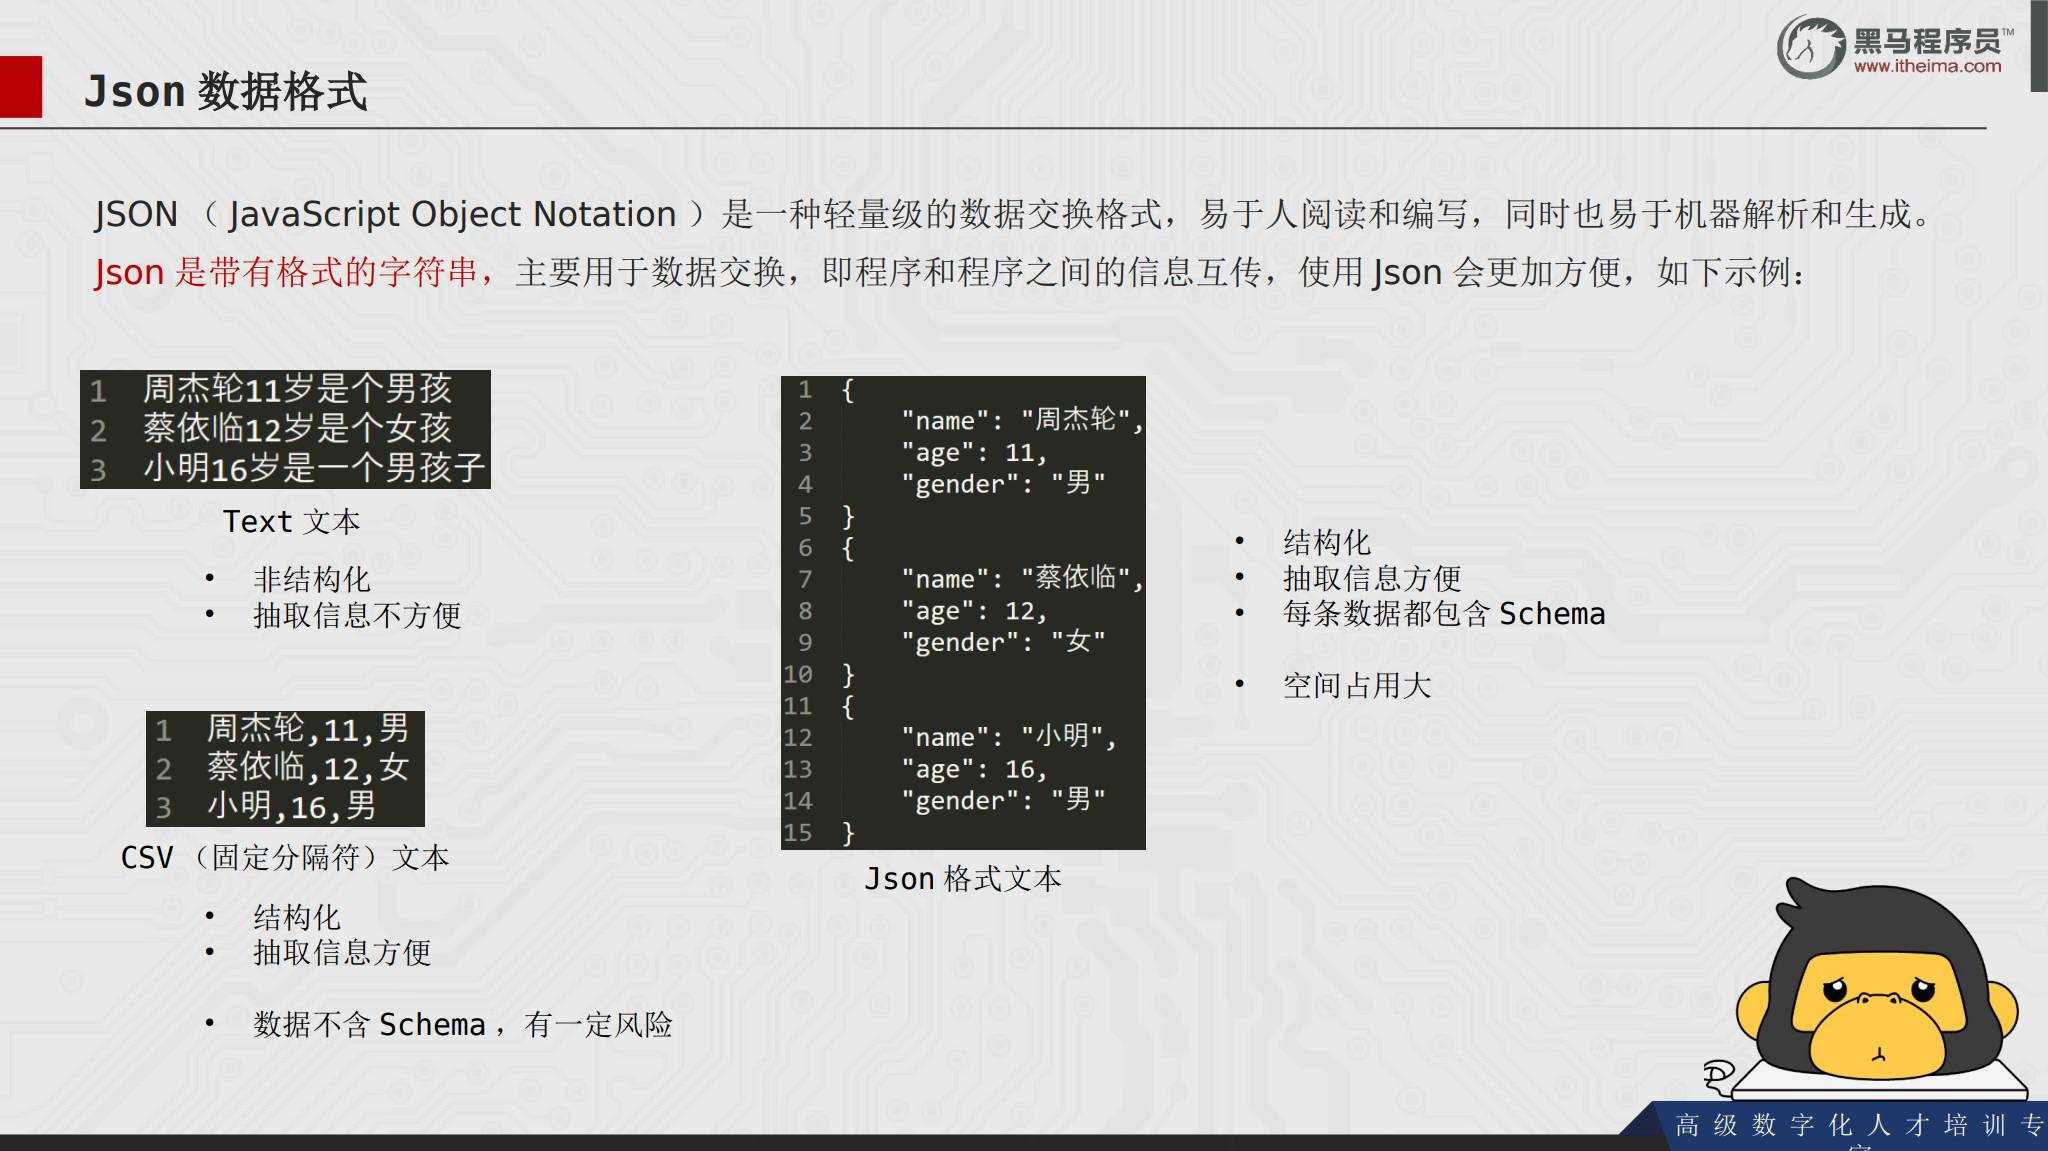


## 28. 金融文本信息抽取：定义 Schema

信息抽取任务需要先定义字段 Schema。课件的金融字段包括：

```python
schema = {
    "金融": ["日期", "股票名称", "开盘价", "收盘价", "成交量"],
}
```

模型的任务是从股票信息文本中抽取这些字段，并以 JSON 输出。输入文本可能含有未提及字段，因此 Prompt 需要规定：缺失信息统一写成 `['原文中未提及']`，多个值用逗号分隔。

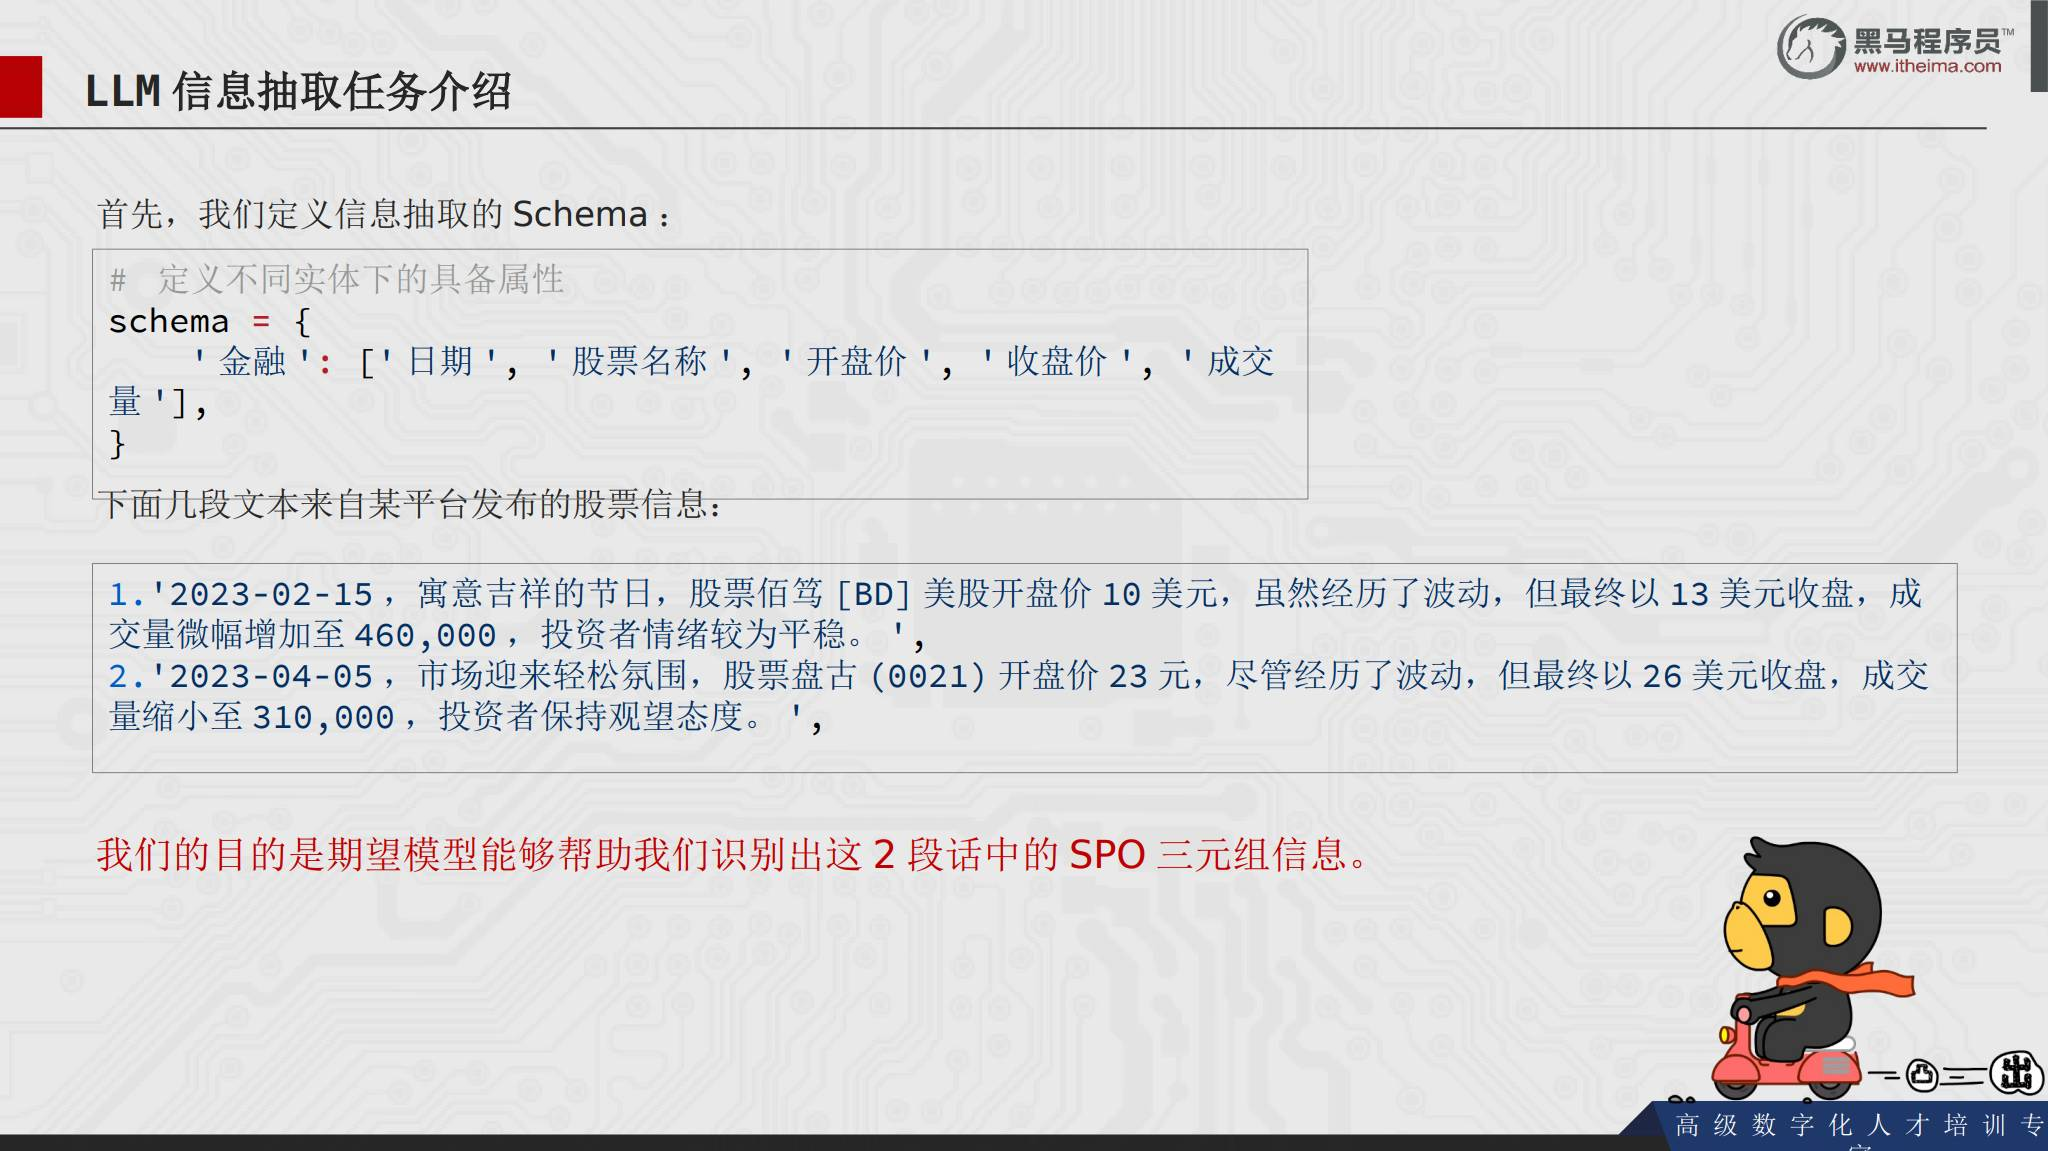


## 29. 用 Few-shot 规范抽取结果

为了让模型理解“信息抽取”具体是什么，课件给出人工准备的 User/Bot 示例：

```text
User：请从下面句子中提取“金融”类型实体，字段为
日期、股票名称、开盘价、收盘价、成交量，并按 JSON 输出。
缺失字段写“原文中未提及”。

Bot：{
  "日期": ["2023-01-10"],
  "股票名称": ["示例股票"],
  "开盘价": ["100 美元"],
  "收盘价": ["102 美元"],
  "成交量": ["520000"]
}
```

示例中的 Bot 内容由人工提供，用来规定模型看到类似 User 输入时应该如何回答。Few-shot 的关键不是示例数量越多越好，而是示例要覆盖字段、格式和缺失值规则。

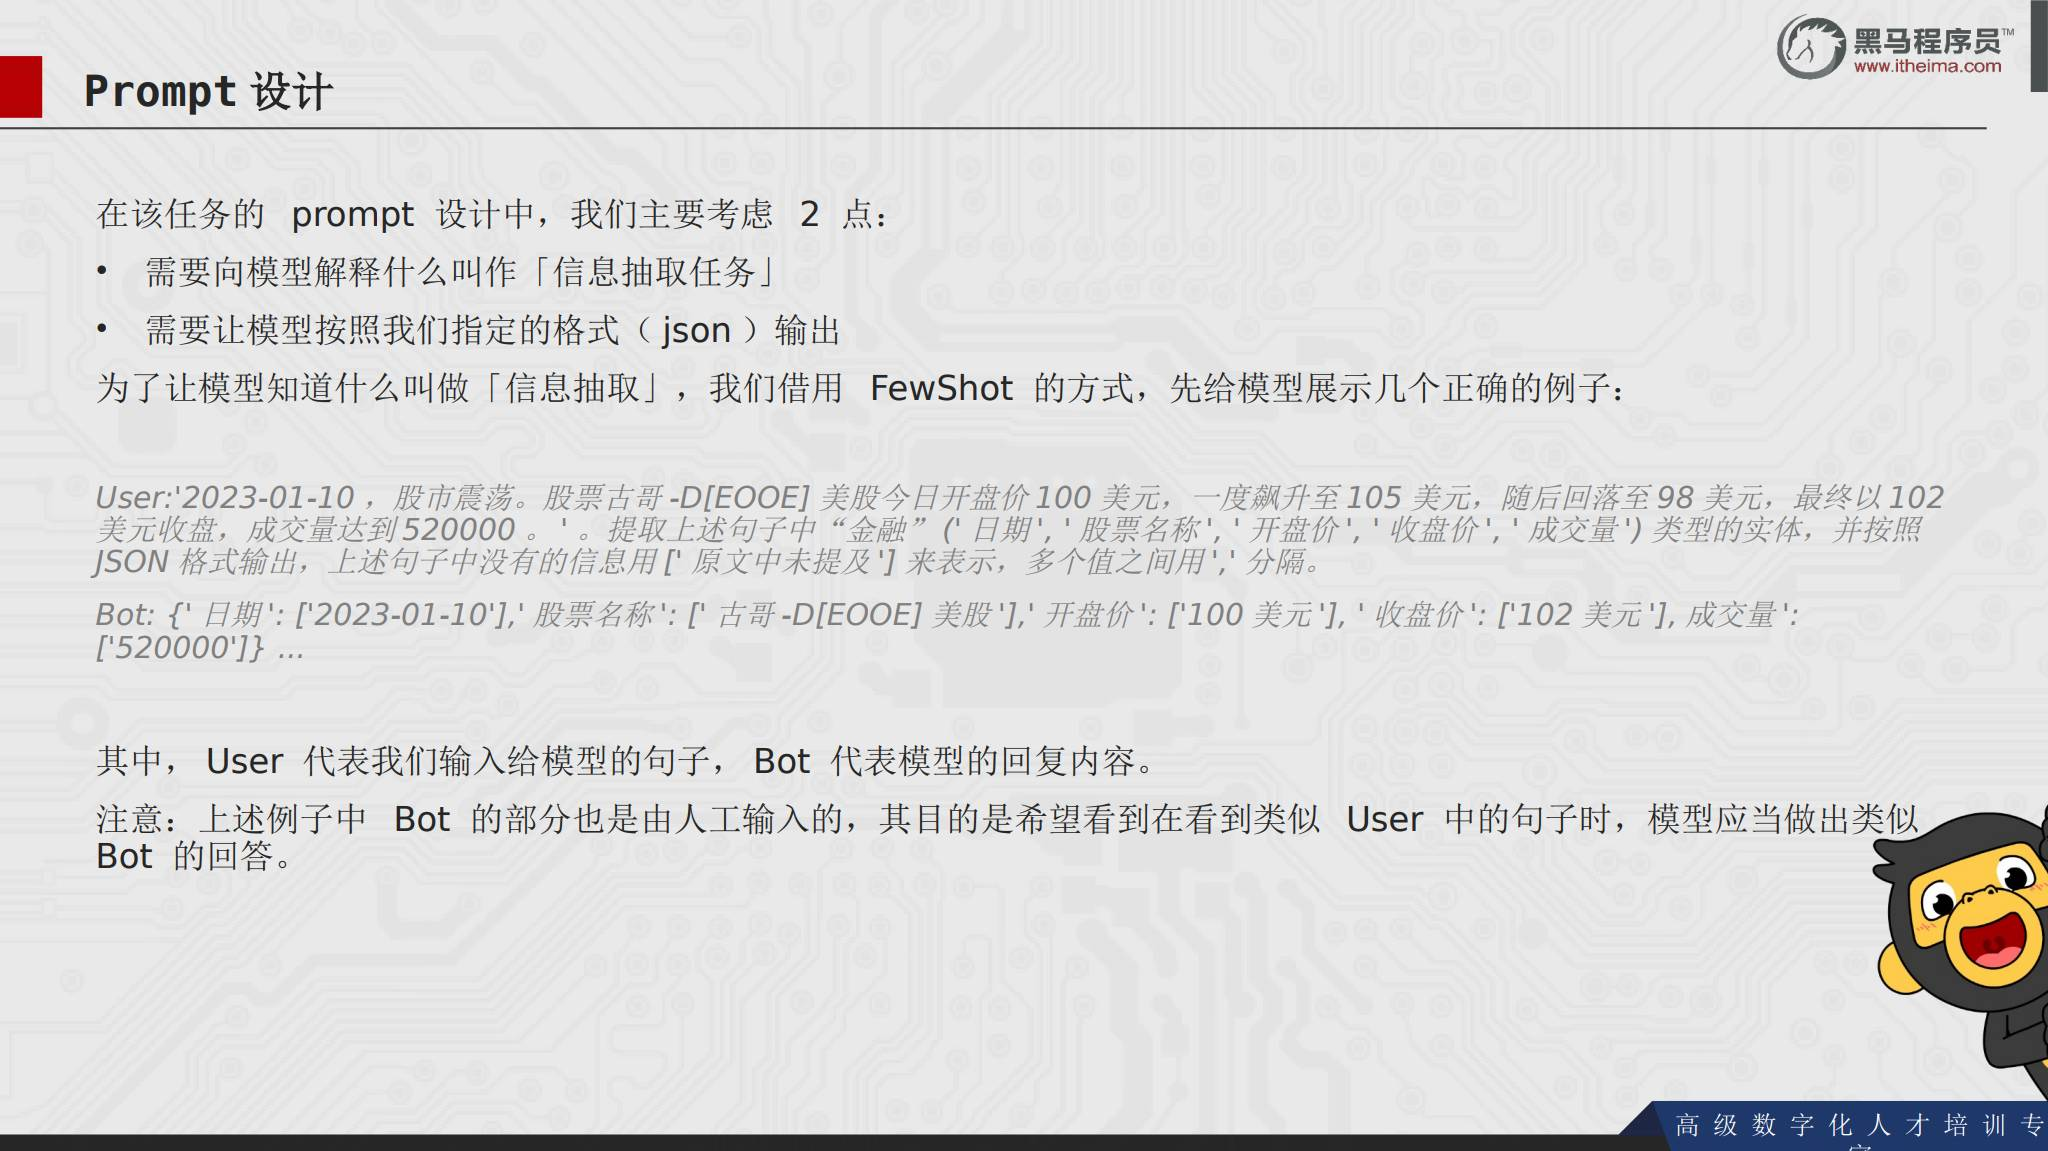


## 30. 信息抽取的代码处理链

课件将信息抽取实现拆成四个部分：

1. 构造 Prompt 和 Few-shot 历史消息。
2. 调用模型生成抽取结果。
3. 清理模型可能包裹的 Markdown JSON 代码块。
4. 用 `json.loads()` 尝试解析为 Python 数据。

```python
def clean_response(response: str):
    if ("`" * 3 + "json") in response:
        match = re.findall(r"`{3}json(.*?)`{3}", response, flags=re.S)
        if match and match[0]:
            response = match[0]
    response = response.replace("、", ",")
    try:
        return json.loads(response)
    except json.JSONDecodeError:
        return response
```

清理函数不能代替业务校验。解析失败时保留原始文本，便于记录问题并继续处理错误。

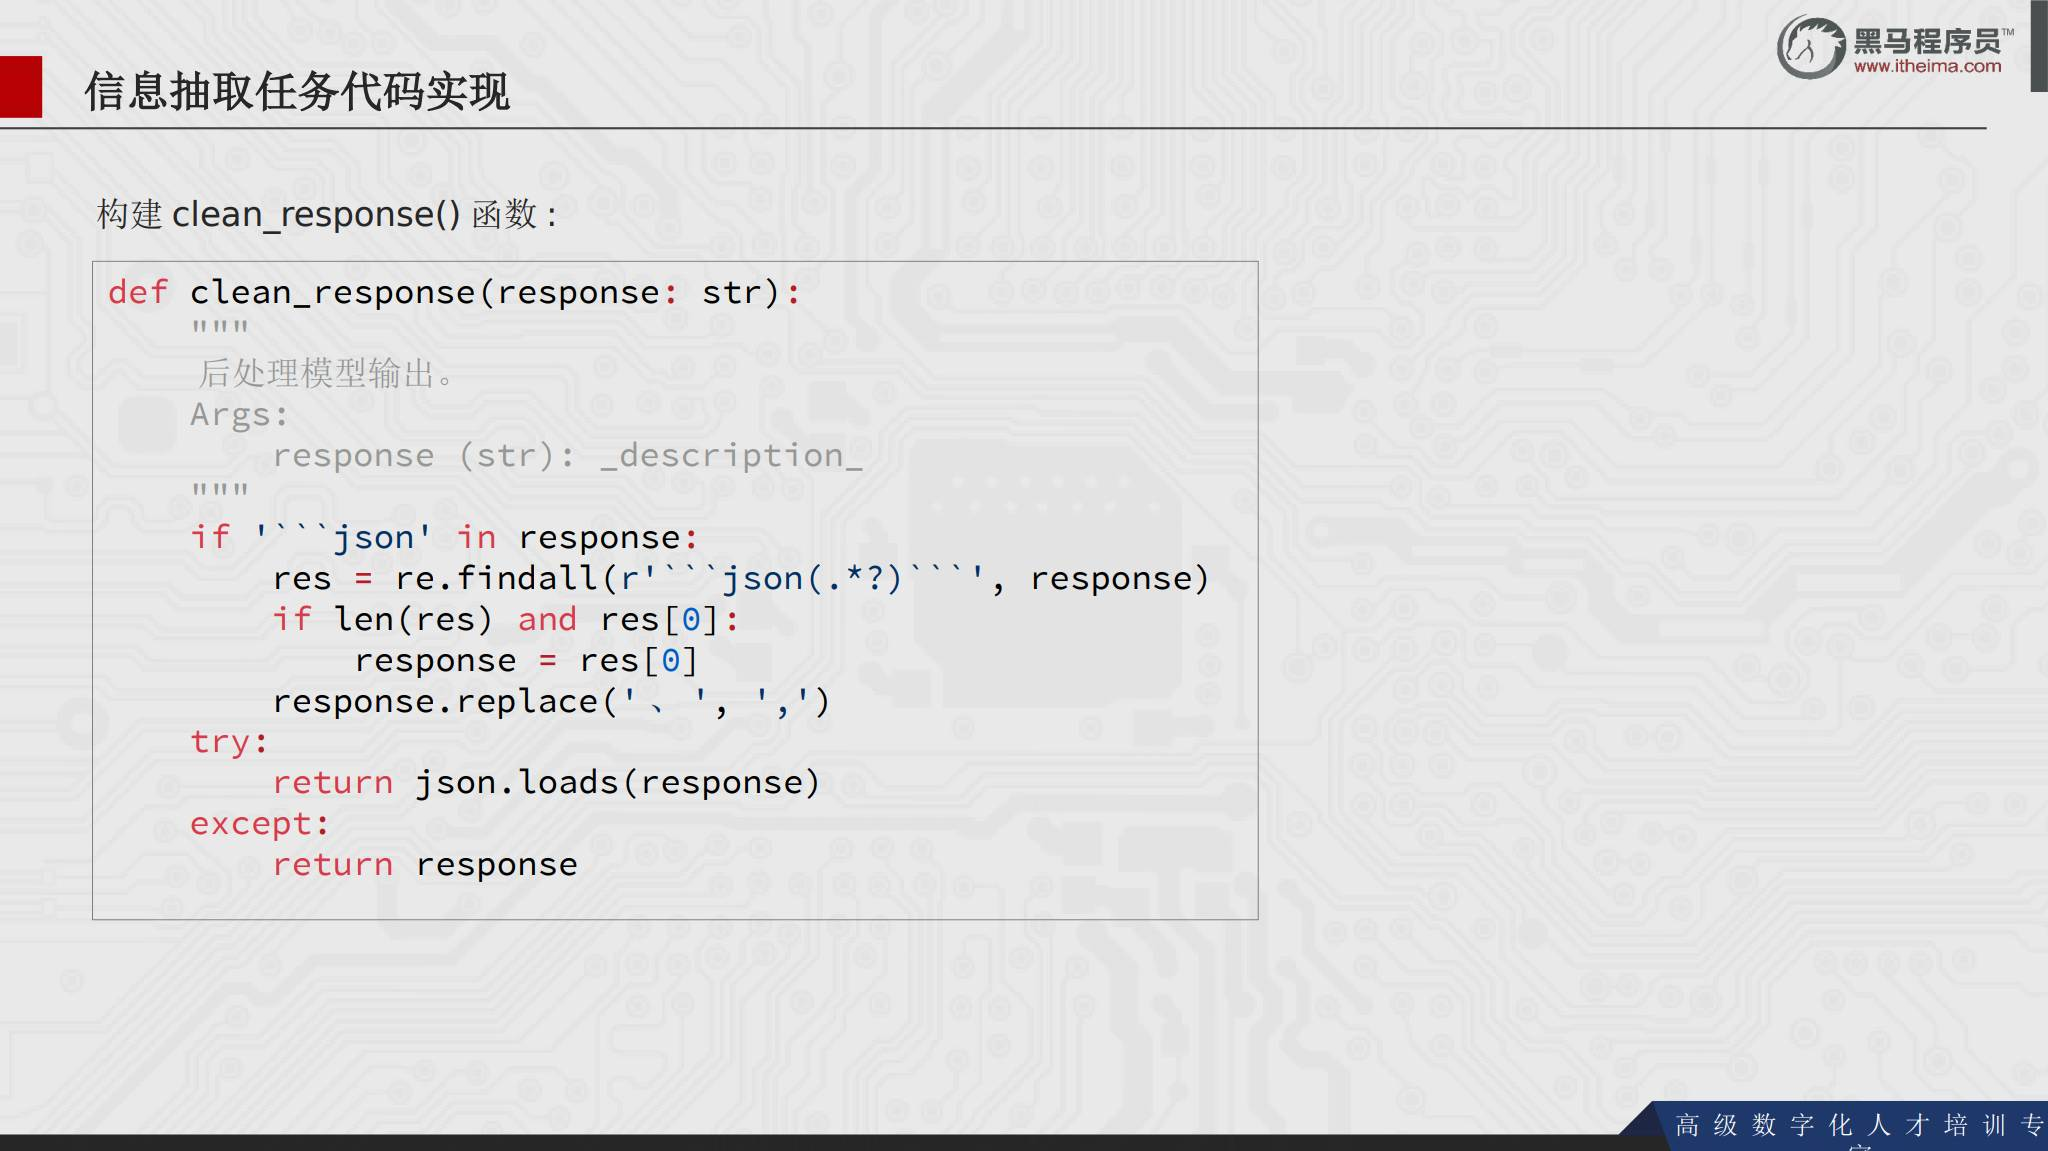


## 31. 信息抽取调用模型

模型调用函数可以接收当前 Prompt、客户端和历史消息：

```python
def qwen_model(prompt, client, history=None):
    history = history or []
    completion = client.chat.completions.create(
        model=os.getenv("MODEL"),
        messages=history + [{"role": "user", "content": prompt}],
    )
    return completion.choices[0].message.content
```

主流程先用 `init_prompt()` 生成历史示例，再遍历待抽取句子，调用模型并执行 `clean_response()`。这样既保存了原始模型输出，也得到尽量结构化的结果。


## 32. 信息抽取练习：彩票文本

课件给出的练习要求从彩票文本中抽取期数、中奖号码和一等奖等字段，并通过 Few-shot 设计 Prompt，使模型输出类似 JSON 的结果。

这个练习迁移了金融抽取案例的思路：先定义字段，再提供示例，规定缺失信息和输出格式，最后解析模型结果。字段和示例数据来自课程练习，不应把模型输出直接当作事实，仍需进行格式和业务校验。


## 33. 金融文本匹配

文本匹配任务输入两句话，判断它们的语义是否相关，只输出“是”或“不是”。例如：

- “公司 ABC 发布季度财报，显示盈利增长”与“财报披露，公司 ABC 利润上升”属于相关表达。
- “黄金价格下跌，投资者抛售”与“外汇市场交易额创下新高”不属于同一语义。

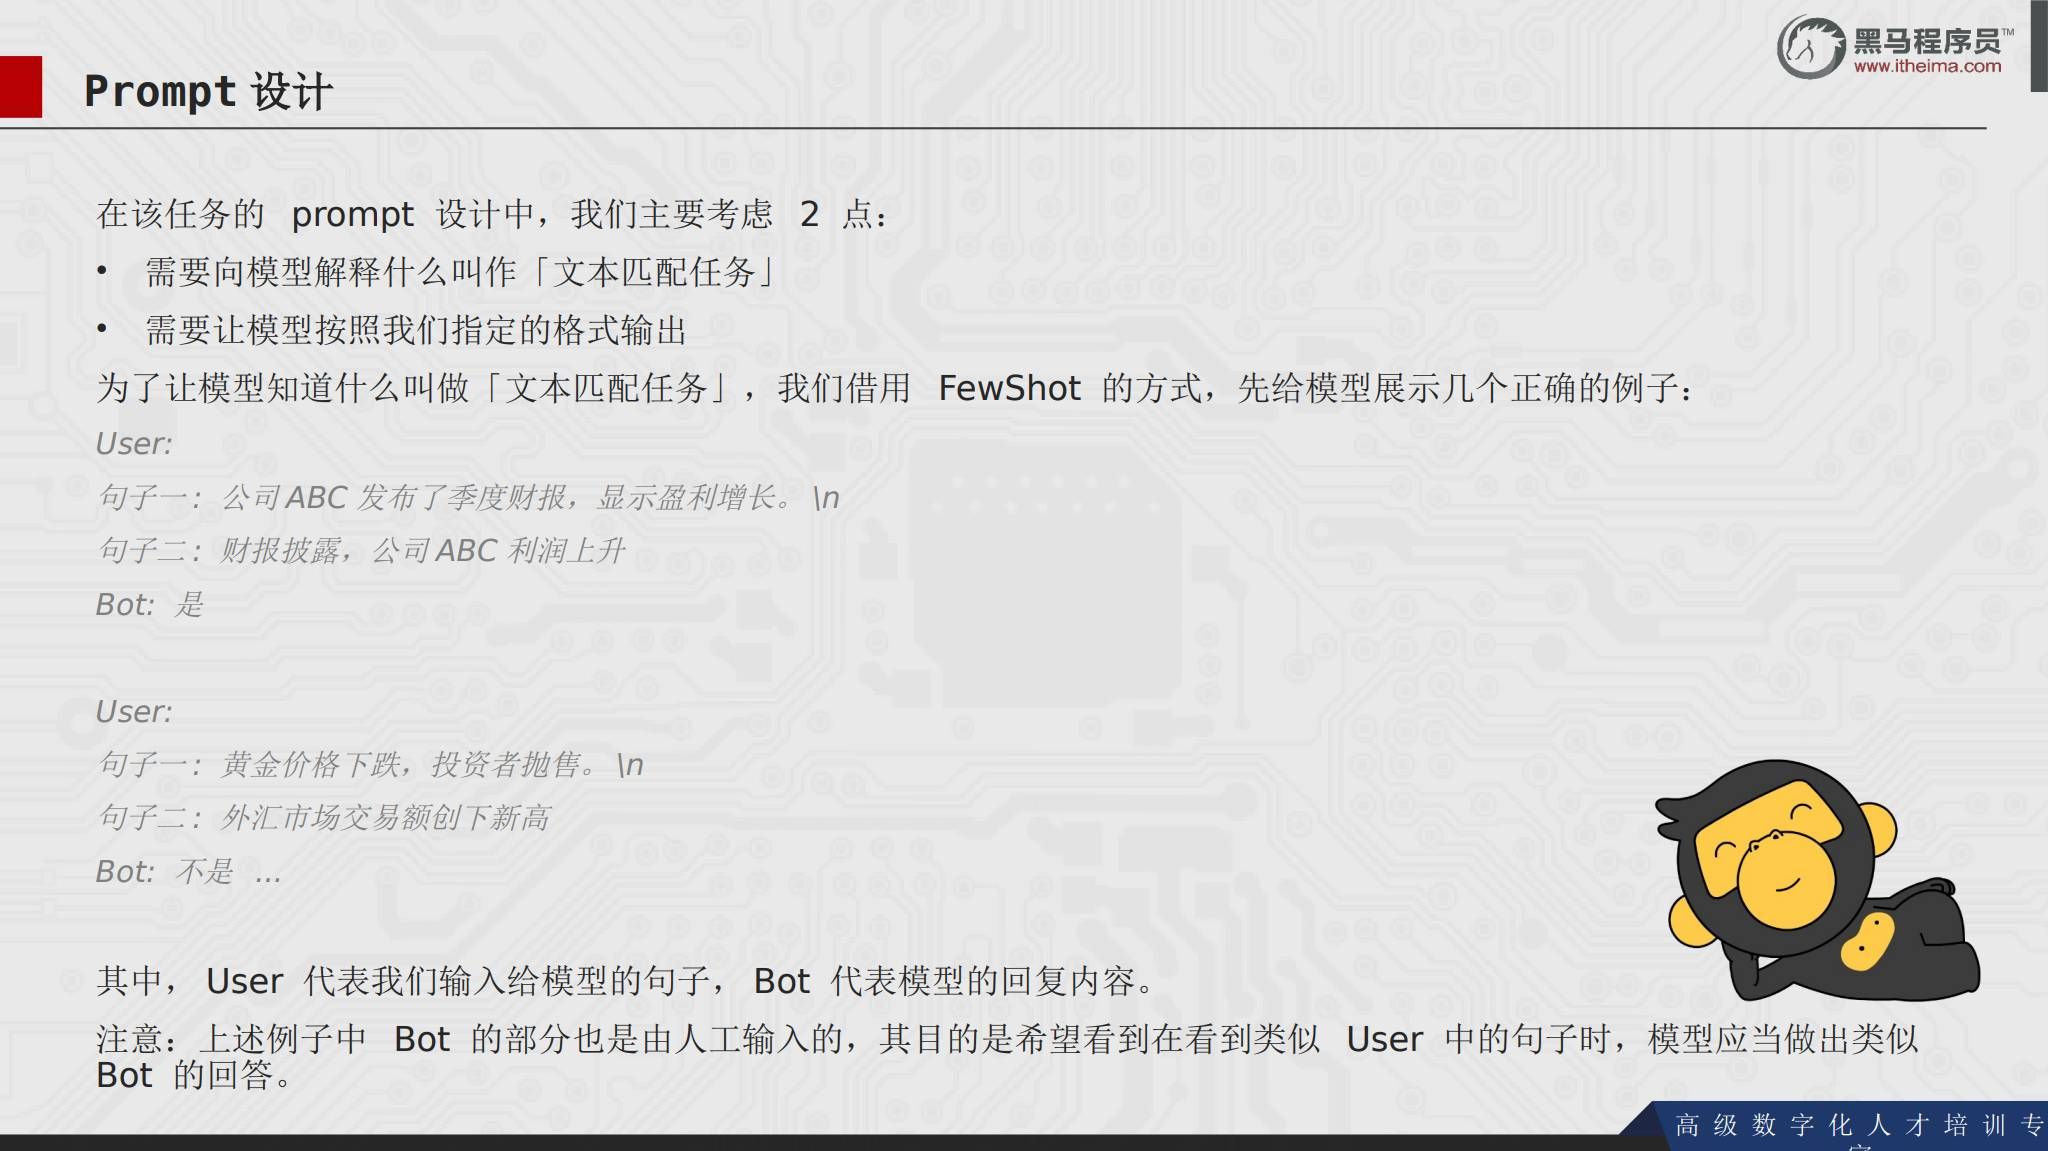


## 34. 文本匹配 Prompt 与代码结构

匹配任务的系统规则需要限制输出，不要让模型添加解释：

```text
判断两个句子的语义是否相似。
相似只返回“是”，不相似只返回“不是”，不要其他回答。

句子一：{sentence_a}
句子二：{sentence_b}
是否是语义相同的句子？
```

再通过 Few-shot 添加“是”和“不是”的示例，帮助模型对齐判断标准。代码结构与分类任务相似：准备 `examples`，构造 `history`，把待匹配句对追加为最后一条用户消息，再读取模型回答。


## 35. 三类任务的共同方法

金融文本分类、信息抽取和文本匹配的共同流程是：

1. 明确任务目标和输出格式。
2. 用系统消息写角色、规则和边界。
3. 需要时提供少量高质量示例。
4. 将待处理文本放入最后一条用户消息。
5. 读取模型结果并做格式解析或校验。

三类任务的输出约束不同：分类输出一个标签，抽取输出 JSON，匹配输出“是/不是”。任务设计越明确，后处理越容易。


## 36. 本章小结

本篇完成了从模型调用到提示词实战的基础链路：

- 用 API Key 和 OpenAI SDK 调用云端模型。
- 用环境变量保护密钥。
- 用 Ollama 在本地运行模型，并通过兼容接口调用。
- 理解 `messages`、三种角色、流式输出和历史消息。
- 认识 LLM 的架构分类和主流模型。
- 用清晰描述、角色、分隔符、步骤、示例和参考文档设计 Prompt。
- 用 Zero-shot 和 Few-shot 完成金融文本分类、信息抽取和匹配。

后续 RAG 课程会把这些基础能力接到文档加载、向量检索和知识库问答中。


## 37. 资料边界

本篇依据第 1 份课件的 96 页内容整理。课件中的云端服务、模型名称、参数规模和 SDK 写法会随平台版本变化；真实 API Key 已全部替换为占位说明。课件只展示了案例主线和关键代码片段，未在本篇补写完整项目工程、生产级密钥管理或模型服务商的最新接口文档。
